# EDA y preparación de datos para predecir ventas diarias de e-commerce

**Dataset:** *E-Commerce Data* (UCI / Kaggle) — transacciones de una tienda online del Reino Unido entre el 01/12/2010 y el 09/12/2011.

**Problema (Tema 2):** predecir el **valor total de ventas diario** entre el 09/11/2011 y el 09/12/2011 (test), usando los datos del 01/12/2010 al 08/11/2011 (train + validación).

Este notebook cubre todo el proceso previo al entrenamiento de los modelos: análisis exploratorio, limpieza, transformación, división de los datos y escalado.

> **Kernel:** `venv_autoeda (3.12)`. La comparación entre herramientas y el motivo de cada una están en [`COMPARATIVA_AUTOEDA.md`](COMPARATIVA_AUTOEDA.md). Los informes HTML completos se muestran dentro del notebook y se guardan en [`eda_reports/combinado/`](eda_reports/combinado/).

In [1]:
import warnings
from html import escape
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import HTML, Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (10, 4)
%config InlineBackend.figure_format = 'retina'

DATA_PATH = '/home/eze/IA-BigData/M_ProyectoIABD/T2/data.csv'
REPORTS = Path('eda_reports/combinado')

def report_file(library, name):
    """Ruta de un informe HTML dentro de la carpeta de su librería."""
    folder = REPORTS / library / 'html'
    folder.mkdir(parents=True, exist_ok=True)
    return folder / name

def show_report(path, height=800):
    """Muestra un informe HTML dentro del notebook, con su enlace al archivo."""
    display(Markdown(f'Informe: [{path}]({path})'))
    report = escape(Path(path).read_text(encoding='utf-8'))
    display(HTML(f'<iframe srcdoc="{report}" width="100%" height="{height}" style="border: 1px solid #ccc"></iframe>'), metadata={'tags': ['informe-html']})

def show_findings(result, report):
    """Guarda el informe HTML de prism-eda y muestra sus hallazgos como tabla."""
    path = report_file('prism', report)
    result.to_html(path)
    display(Markdown(f'> {result.summary}'))
    show_report(path)
    rows = [f'| {f.severity} | {f.title} | {f.summary} | {f.recommendation} |' for f in result.findings]
    display(Markdown('\n'.join(['| Severidad | Hallazgo | Detalle | Recomendación |',
                                '|:------|:------------|:------------------|:---------------|', *rows])))

In [2]:
# Fechas clave del enunciado
TRAIN_START = pd.Timestamp('2010-12-01')
TEST_START  = pd.Timestamp('2011-11-09')
TEST_END    = pd.Timestamp('2011-12-09')

## 1. Carga de datos

In [3]:
# El CSV no es UTF-8 (contiene caracteres latin-1). Leemos los identificadores como texto
# para no perder ceros ni letras (InvoiceNo 'C...', StockCode '85123A').
df = pd.read_csv(
    DATA_PATH,
    encoding='latin-1',
    dtype={'InvoiceNo': str, 'StockCode': str, 'CustomerID': str},
)
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%Y %H:%M')
df['CustomerID'] = df['CustomerID'].str.replace(r'\.0$', '', regex=True)

print(f'Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}')
df.head()

Filas: 541,909 | Columnas: 8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 2. Entendimiento de los datos

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  object        
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(5)
memory usage: 33.1+ MB


In [5]:
# Cardinalidad de cada columna
summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str), # dtype no es un tipo de dato nativo de pandas, lo convertimos a str para que se vea bonito
    'nulos': df.isnull().sum(), # cantidad de valores nulos en cada columna
    '% nulos': (df.isnull().mean() * 100).round(2), # porcentaje de valores nulos en cada columna
    'únicos': df.nunique(), # cantidad de valores únicos en cada columna
    'ejemplo': df.iloc[0], # primer valor de cada columna
})
summary

,dtype,nulos,% nulos,únicos,ejemplo
InvoiceNo,object,0,0.00,25900,536365
StockCode,object,0,0.00,4070,85123A
Description,object,1454,0.27,4223,WHITE HANGING HEART T-LIGHT HOLDER
Quantity,int64,0,0.00,722,6
InvoiceDate,datetime64[ns],0,0.00,23260,2010-12-01 08:26:00
UnitPrice,float64,0,0.00,1630,2.55
CustomerID,object,135080,24.93,4372,17850
Country,object,0,0.00,38,United Kingdom


Casi el 25% de los clientes se desconocen, y tenemos 0.27% de descripciones vacías

In [6]:
df.describe(include=[np.number]).T

,count,mean,std,min,25%,50%,75%,max
Quantity,"541,909.00",9.55,218.08,"-80,995.00",1.00,3.00,10.00,"80,995.00"
UnitPrice,"541,909.00",4.61,96.76,"-11,062.06",1.25,2.08,4.13,"38,970.00"


Podemos ver que hay valores que se desvían muchísimo de la media, son claros outliers que tenemos que tener en cuenta para la limpieza de datos. Por ejemplo, hay transacciones con cantidades negativas, que son devoluciones, y transacciones con cantidades muy altas, que son compras al por mayor.

### 2.1. Informe general (ydata-profiling)

Generamos un informe del dataset original y leemos sus alertas desde Python.

In [ ]:
from ydata_profiling import ProfileReport
%matplotlib inline

raw_profile = ProfileReport(df, title='E-Commerce Data (original) - ydata-profiling', progress_bar=False)
raw_desc = raw_profile.get_description()
report = report_file('ydata', '1_ydata_original.html')
raw_profile.to_file(report)
show_report(report)


  0%|          | 0/8 [00:00<?, ?it/s]


 12%|█▎        | 1/8 [00:02<00:14,  2.13s/it]


 38%|███▊      | 3/8 [00:02<00:03,  1.41it/s]


100%|██████████| 8/8 [00:02<00:00,  3.11it/s]

Informe: [eda_reports/combinado/ydata/html/1_ydata_original.html](eda_reports/combinado/ydata/html/1_ydata_original.html)

In [8]:
# Alertas del informe
pd.DataFrame({
    'tipo': [a.alert_type.name for a in raw_desc.alerts],
    'detalle': [str(a) for a in raw_desc.alerts],
})

,tipo,detalle
0,DUPLICATES,Dataset has 4879 (0.9%) duplicate rows
1,HIGH_CORRELATION,[Country] is highly overall correlated with [CustomerID]
2,HIGH_CORRELATION,[CustomerID] is highly overall correlated with [Country]
3,IMBALANCE,[Country] is highly imbalanced (0.8588886496271749)
4,MISSING,[CustomerID] 135080 (24.9%) missing values
5,SKEWED,[UnitPrice] is highly skewed(γ1 = 186.50697172054137)


De las alertas, los nulos de `CustomerID` ya eran conocidos. Lo nuevo es que `UnitPrice` es extremadamente asimétrico (asimetría de 187), que `Country` está muy desequilibrado y que hay filas duplicadas.

### 2.2. Tipos de factura (`InvoiceNo`)

In [9]:
# Las facturas que empiezan por 'C' son cancelaciones; buscamos otros prefijos no numéricos
inv_prefix = df['InvoiceNo'].str.extract(r'^([A-Za-z]*)')[0].replace('', 'numérica')
inv_prefix.value_counts()

0
numérica    532618
C             9288
A                3
Name: count, dtype: int64

In [10]:
cancel = df['InvoiceNo'].str.startswith('C')
print(f'Líneas canceladas: {cancel.sum():,} ({cancel.mean():.2%})')
print('¿Todas las cancelaciones tienen Quantity < 0?', (df.loc[cancel, 'Quantity'] < 0).all())
print('Líneas con Quantity < 0 que NO son cancelación:', ((df['Quantity'] < 0) & ~cancel).sum())
df[df['InvoiceNo'].str.startswith('A')]

Líneas canceladas: 9,288 (1.71%)
¿Todas las cancelaciones tienen Quantity < 0? True
Líneas con Quantity < 0 que NO son cancelación: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,"11,062.06",NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",NaN,United Kingdom


- Las facturas **`C`** son cancelaciones/devoluciones y siempre tienen `Quantity` negativa.
- Las facturas **`A`** son *"Adjust bad debt"*: ajustes contables, no ventas reales.
- Hay líneas con `Quantity < 0` que no son cancelaciones.

### 2.3. Códigos de producto (`StockCode`) no estándar

In [11]:
# El patrón habitual es 5 dígitos, opcionalmente seguidos de letras (p.ej. 85123A)
std_code = df['StockCode'].str.match(r'^\d{5}[A-Za-z]*$')
print(f'Líneas con StockCode no estándar: {(~std_code).sum():,} ({(~std_code).mean():.2%})')

special = (df[~std_code]
           .groupby('StockCode')
           .agg(descripcion=('Description', lambda s: s.mode().iat[0] if s.notna().any() else None),
                lineas=('StockCode', 'size'),
                importe_total=('UnitPrice', lambda s: (s * df.loc[s.index, 'Quantity']).sum()))
           .sort_values('lineas', ascending=False))
special

Líneas con StockCode no estándar: 2,995 (0.55%)


,descripcion,lineas,importe_total
StockCode,,,
POST,POSTAGE,1256,"66,230.64"
DOT,DOTCOM POSTAGE,710,"206,245.48"
M,Manual,571,"-68,674.19"
C2,CARRIAGE,144,"6,986.00"
D,Discount,77,"-5,696.22"
S,SAMPLES,63,"-3,049.39"
BANK CHARGES,Bank Charges,37,"-7,175.64"
AMAZONFEE,AMAZON FEE,34,"-221,520.50"
CRUK,CRUK Commission,16,"-7,933.43"


Los códigos no estándar corresponden a **conceptos que no son productos**: gastos de envío (`POST`, `DOT`), comisiones (`BANK CHARGES`, `AMAZONFEE`), ajustes manuales (`M`), descuentos (`D`), muestras (`S`), regalos (`gift_...`), etc.
Algunos mueven importes muy grandes (p.ej. `AMAZONFEE`, `M`), por lo que habrá que decidir si cuentan como "ventas" o no.

### 2.4. Descripciones

In [12]:
desc_counts = df['Description'].value_counts()
print('Descripciones únicas:', desc_counts.size)
print('StockCodes con más de una descripción:',
      (df.groupby('StockCode')['Description'].nunique() > 1).sum())
desc_counts.head(15)

Descripciones únicas: 4223


StockCodes con más de una descripción: 650


Description
WHITE HANGING HEART T-LIGHT HOLDER    2369
REGENCY CAKESTAND 3 TIER              2200
JUMBO BAG RED RETROSPOT               2159
PARTY BUNTING                         1727
LUNCH BAG RED RETROSPOT               1638
ASSORTED COLOUR BIRD ORNAMENT         1501
SET OF 3 CAKE TINS PANTRY DESIGN      1473
PACK OF 72 RETROSPOT CAKE CASES       1385
LUNCH BAG  BLACK SKULL.               1350
NATURAL SLATE HEART CHALKBOARD        1280
POSTAGE                               1252
JUMBO BAG PINK POLKADOT               1251
HEART OF WICKER SMALL                 1237
JAM MAKING SET WITH JARS              1229
JUMBO STORAGE BAG SUKI                1214
Name: count, dtype: int64

In [13]:
# Descripciones en minúsculas / sin sentido: suelen ser notas internas de almacén
desc = df['Description'].dropna()
odd_desc = desc[~desc.str.isupper().astype(bool)]
odd_desc.value_counts().head(25)

Description
Manual                                 572
BAG 125g SWIRLY MARBLES                304
BAG 250g SWIRLY MARBLES                252
3 TRADITIONAl BISCUIT CUTTERS  SET     240
POLYESTER FILLER PAD 40x40cm           193
FRENCH BLUE METAL DOOR SIGN No         167
check                                  159
BAG 500g SWIRLY MARBLES                146
POLYESTER FILLER PAD 45x45cm           144
Next Day Carriage                       80
Discount                                77
?                                       47
damages                                 45
damaged                                 43
POLYESTER FILLER PAD 45x30cm            38
Bank Charges                            37
NUMBER TILE VINTAGE FONT No             35
NUMBER TILE COTTAGE GARDEN No           34
ESSENTIAL BALM 3.5g TIN IN ENVELOPE     31
POLYESTER FILLER PAD 30CMx30CM          26
found                                   25
sold as set on dotcom                   20
adjustment                              16

Las descripciones de productos reales están en MAYÚSCULAS. Las descripciones en minúsculas (`damaged`, `check`, `?`, `wet damaged`, `found`, …) son **anotaciones internas** de inventario, normalmente con `UnitPrice = 0` y cantidades negativas.

### 2.5. Países

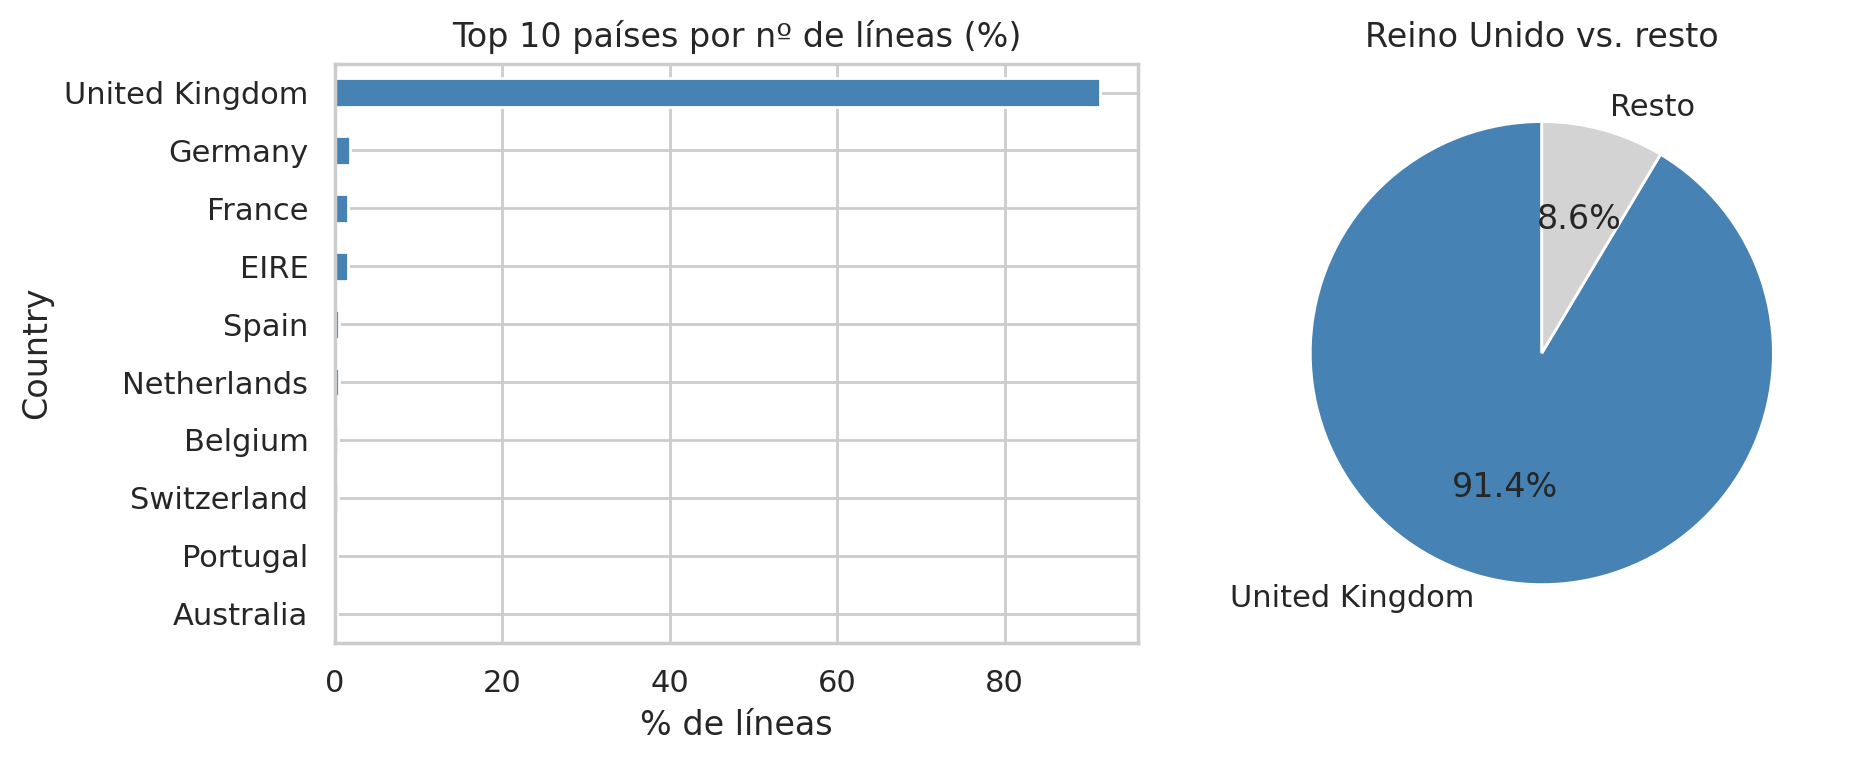

Country
Unspecified           446
European Community     61
Name: count, dtype: int64


In [14]:
country = df['Country'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
(country / country.sum() * 100).head(10).plot.barh(ax=axes[0], color='steelblue')
axes[0].invert_yaxis()
axes[0].set_title('Top 10 países por nº de líneas (%)')
axes[0].set_xlabel('% de líneas')

uk = (df['Country'] == 'United Kingdom').mean()
axes[1].pie([uk, 1 - uk], labels=['United Kingdom', 'Resto'], autopct='%1.1f%%',
            colors=['steelblue', 'lightgray'], startangle=90)
axes[1].set_title('Reino Unido vs. resto')
plt.tight_layout(); plt.show()

print(country[country.index.isin(['Unspecified', 'European Community'])])

El ~91% de las transacciones son del Reino Unido. Existen valores poco informativos como `Unspecified` o `European Community`.

## 3. Valores faltantes, duplicados y erróneos

### 3.1. Valores faltantes

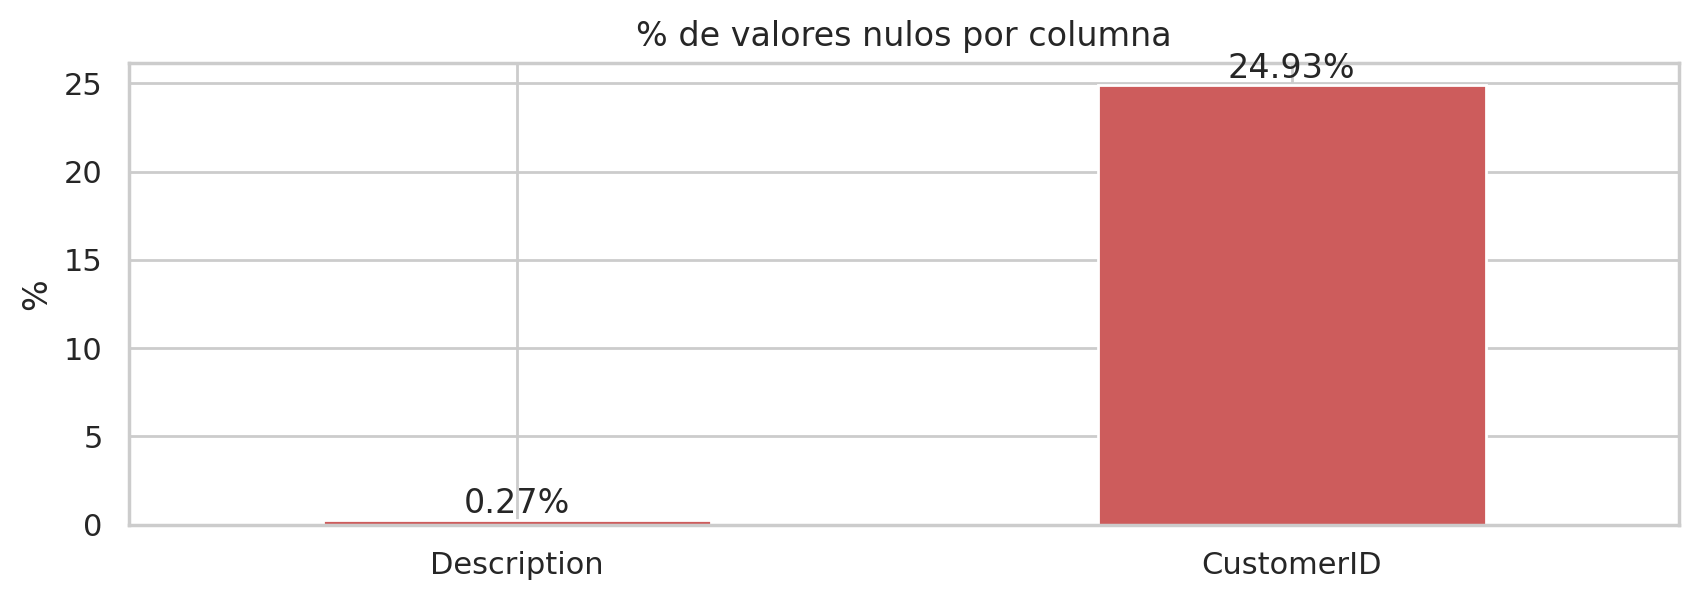

,nulos,%
Description,1454,0.27
CustomerID,135080,24.93


In [15]:
missing = df.isnull().sum().to_frame('nulos')
missing['%'] = missing['nulos'] / len(df) * 100
missing = missing[missing['nulos'] > 0]

ax = missing['%'].plot.bar(color='indianred', figsize=(10, 3), rot=0)
ax.set_title('% de valores nulos por columna'); ax.set_ylabel('%')
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.show()
missing

In [16]:
no_desc = df['Description'].isnull()
print('Filas sin descripción:', no_desc.sum())
print('  - de ellas con CustomerID nulo:', df.loc[no_desc, 'CustomerID'].isnull().sum())
print('  - de ellas con UnitPrice == 0: ', (df.loc[no_desc, 'UnitPrice'] == 0).sum())

Filas sin descripción: 1454
  - de ellas con CustomerID nulo: 1454
  - de ellas con UnitPrice == 0:  1454


con cliente  sin cliente
mean Quantity         12.06         2.00
     UnitPrice         3.46         8.08
50%  Quantity          5.00         1.00
     UnitPrice         1.95         3.29
max  Quantity     80,995.00     5,568.00
     UnitPrice    38,970.00    17,836.46

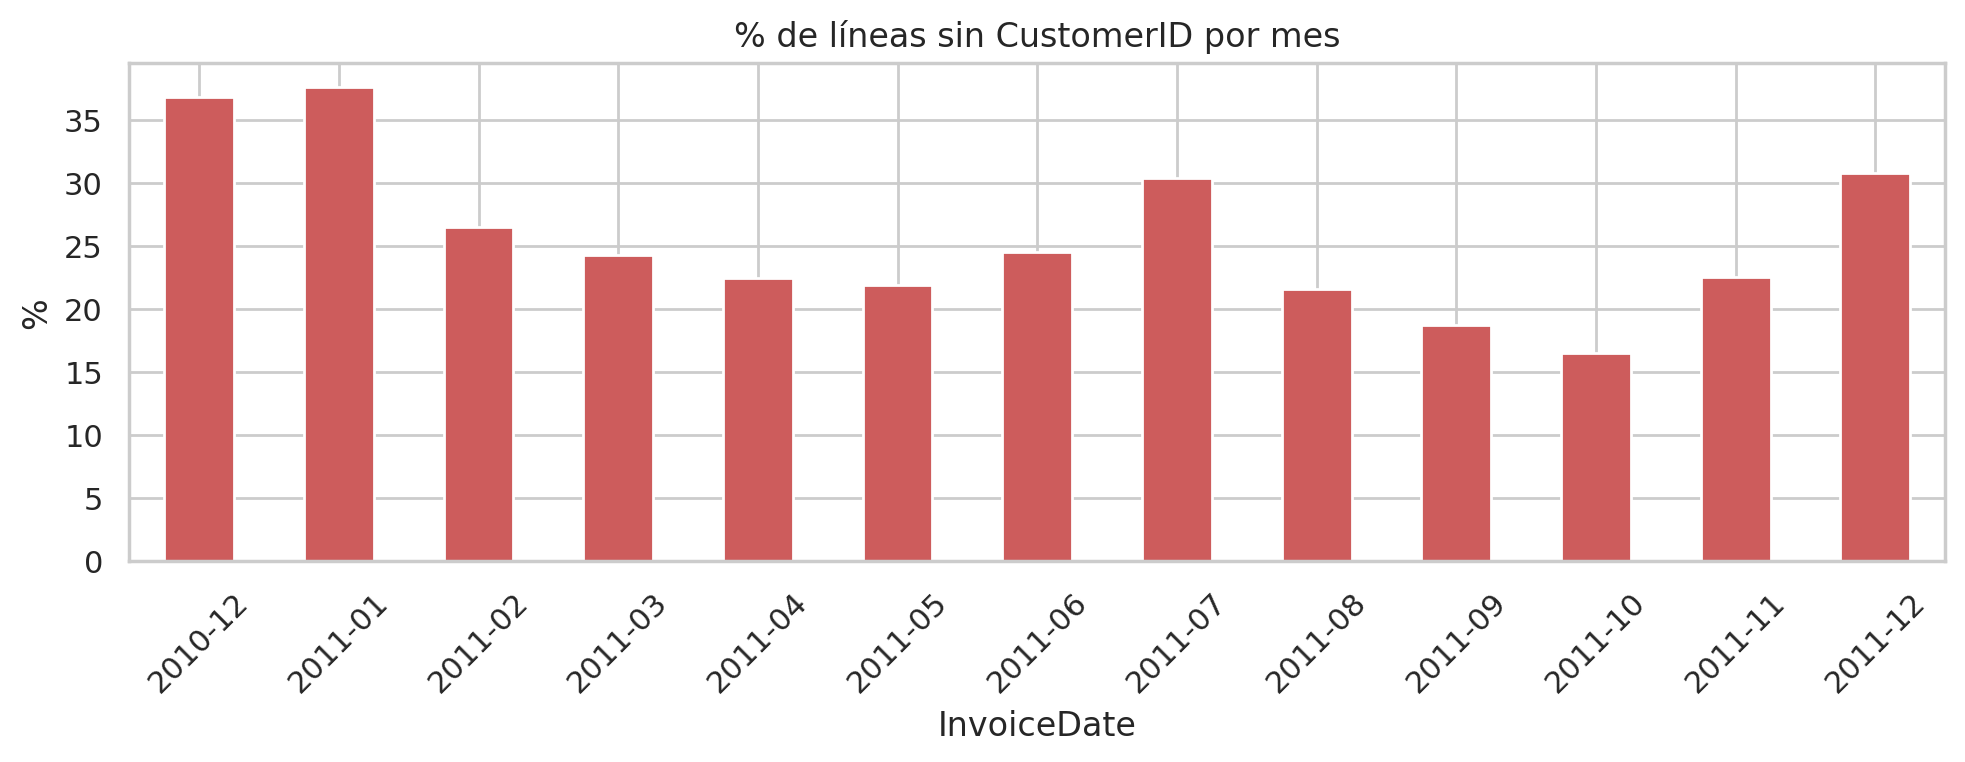

Importe de líneas sin cliente: £1,447,682 (14.9% del total)


In [17]:
no_cust = df['CustomerID'].isnull()
cmp = pd.DataFrame({
    'con cliente': df.loc[~no_cust, ['Quantity', 'UnitPrice']].describe().loc[['mean', '50%', 'max']].stack(),
    'sin cliente': df.loc[no_cust, ['Quantity', 'UnitPrice']].describe().loc[['mean', '50%', 'max']].stack(),
})
display(cmp)

# ¿Las filas sin cliente se concentran en ciertos días o están repartidas?
share_by_month = no_cust.groupby(df['InvoiceDate'].dt.to_period('M')).mean() * 100
ax = share_by_month.plot.bar(color='indianred', rot=45)
ax.set_title('% de líneas sin CustomerID por mes'); ax.set_ylabel('%')
plt.tight_layout(); plt.show()

sales_no_cust = (df.loc[no_cust, 'Quantity'] * df.loc[no_cust, 'UnitPrice']).sum()
sales_total = (df['Quantity'] * df['UnitPrice']).sum()
print(f'Importe de líneas sin cliente: £{sales_no_cust:,.0f} ({sales_no_cust / sales_total:.1%} del total)')

**Conclusiones sobre los nulos**

- **`Description`** (~0,27%): prácticamente todas las filas sin descripción tienen `UnitPrice = 0` y no tienen cliente → no aportan ventas, son candidatas a eliminarse.
- **`CustomerID`** (~25%): un volumen muy alto y repartido en todos los meses, y representa una parte relevante del importe. Para el **problema de regresión** (ventas diarias totales) el cliente no es necesario, así que **eliminarlas perdería ventas reales**. Para el problema de **clustering** (Tema 3) sí habrá que descartarlas.

### 3.2. Duplicados

In [18]:
dup = df.duplicated(keep=False)
print(f'Filas duplicadas exactas: {df.duplicated().sum():,} ({df.duplicated().mean():.2%})')
df[dup].sort_values(['InvoiceNo', 'StockCode']).head(10)

Filas duplicadas exactas: 5,268 (0.97%)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920,United Kingdom


Existen 5.268 filas idénticas (misma factura, producto, cantidad, fecha y precio). ydata-profiling daba 4.879 porque cuenta las filas distintas que se repiten, mientras que `df.duplicated()` cuenta cada repetición. Lo más probable es que sean errores de registro, aunque podría tratarse de líneas legítimamente repetidas en la misma factura.

### 3.3. Valores erróneos o incoherentes

In [19]:
checks = {
    'Quantity < 0':                        df['Quantity'] < 0,
    'Quantity == 0':                       df['Quantity'] == 0,
    'UnitPrice < 0':                       df['UnitPrice'] < 0,
    'UnitPrice == 0':                      df['UnitPrice'] == 0,
    'Quantity < 0 y no es cancelación':    (df['Quantity'] < 0) & ~cancel,
    'Cancelación (InvoiceNo C...)':        cancel,
    'StockCode no estándar':               ~std_code,
}
pd.DataFrame({
    'filas': {k: v.sum() for k, v in checks.items()},
    '%':     {k: v.mean() * 100 for k, v in checks.items()},
})

,filas,%
Quantity < 0,10624,1.96
Quantity == 0,0,0.00
UnitPrice < 0,2,0.00
UnitPrice == 0,2515,0.46
Quantity < 0 y no es cancelación,1336,0.25
Cancelación (InvoiceNo C...),9288,1.71
StockCode no estándar,2995,0.55


In [20]:
# Precio negativo y precio cero
display(df[df['UnitPrice'] < 0])
display(df[df['UnitPrice'] == 0].sample(8, random_state=0))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,"-11,062.06",NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,"-11,062.06",NaN,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
395529,571035,M,Manual,1,2011-10-13 12:50:00,0.00,12446,RSA
173242,551664,20933,NaN,-3,2011-05-03 12:34:00,0.00,NaN,United Kingdom
193218,553521,22362,GLASS JAR PEACOCK BATH SALTS,1,2011-05-17 14:35:00,0.00,NaN,United Kingdom
497819,578476,72807B,????missing,-124,2011-11-24 12:45:00,0.00,NaN,United Kingdom
108688,545566,37477D,NaN,-9,2011-03-03 16:14:00,0.00,NaN,United Kingdom
415316,572534,35597D,NaN,-2,2011-10-24 16:07:00,0.00,NaN,United Kingdom
267089,560283,23196,VINTAGE LEAF MAGNETIC NOTEPAD,12,2011-07-18 08:32:00,0.00,NaN,EIRE
521408,580366,22923,FRIDGE MAGNETS LES ENFANTS ASSORTED,6,2011-12-02 16:38:00,0.00,NaN,United Kingdom


In [21]:
# Cantidades negativas que no son cancelaciones: ajustes de stock sin precio
neg_not_cancel = df[(df['Quantity'] < 0) & ~cancel]
print('UnitPrice de estas filas:', neg_not_cancel['UnitPrice'].unique())
print('Con CustomerID:', neg_not_cancel['CustomerID'].notna().sum())
neg_not_cancel['Description'].value_counts(dropna=False).head(10)

UnitPrice de estas filas: [0.]
Con CustomerID: 0


Description
NaN                       862
check                     120
damages                    45
damaged                    42
?                          41
sold as set on dotcom      20
Damaged                    14
thrown away                 9
Unsaleable, destroyed.      9
??                          7
Name: count, dtype: int64

- Las cantidades negativas **sin** prefijo `C` tienen siempre `UnitPrice = 0` y ningún cliente: son **ajustes de inventario** (roturas, pérdidas…), no ventas.
- Las líneas con `UnitPrice = 0` no generan ingresos; algunas tienen cliente (posibles regalos/promociones).

## 4. Outliers

In [22]:
df['Sales'] = df['Quantity'] * df['UnitPrice']   # importe por línea (columna auxiliar para el análisis)

pct = [.01, .05, .25, .5, .75, .95, .99, .999]
df[['Quantity', 'UnitPrice', 'Sales']].describe(percentiles=pct).T

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,99.9%,max
Quantity,"541,909.00",9.55,218.08,"-80,995.00",-2.00,1.00,1.00,3.00,10.00,29.00,100.00,468.92,"80,995.00"
UnitPrice,"541,909.00",4.61,96.76,"-11,062.06",0.19,0.42,1.25,2.08,4.13,9.95,18.00,205.56,"38,970.00"
Sales,"541,909.00",17.99,378.81,"-168,469.60",-6.58,0.83,3.40,9.75,17.40,59.40,180.00,825.00,"168,469.60"


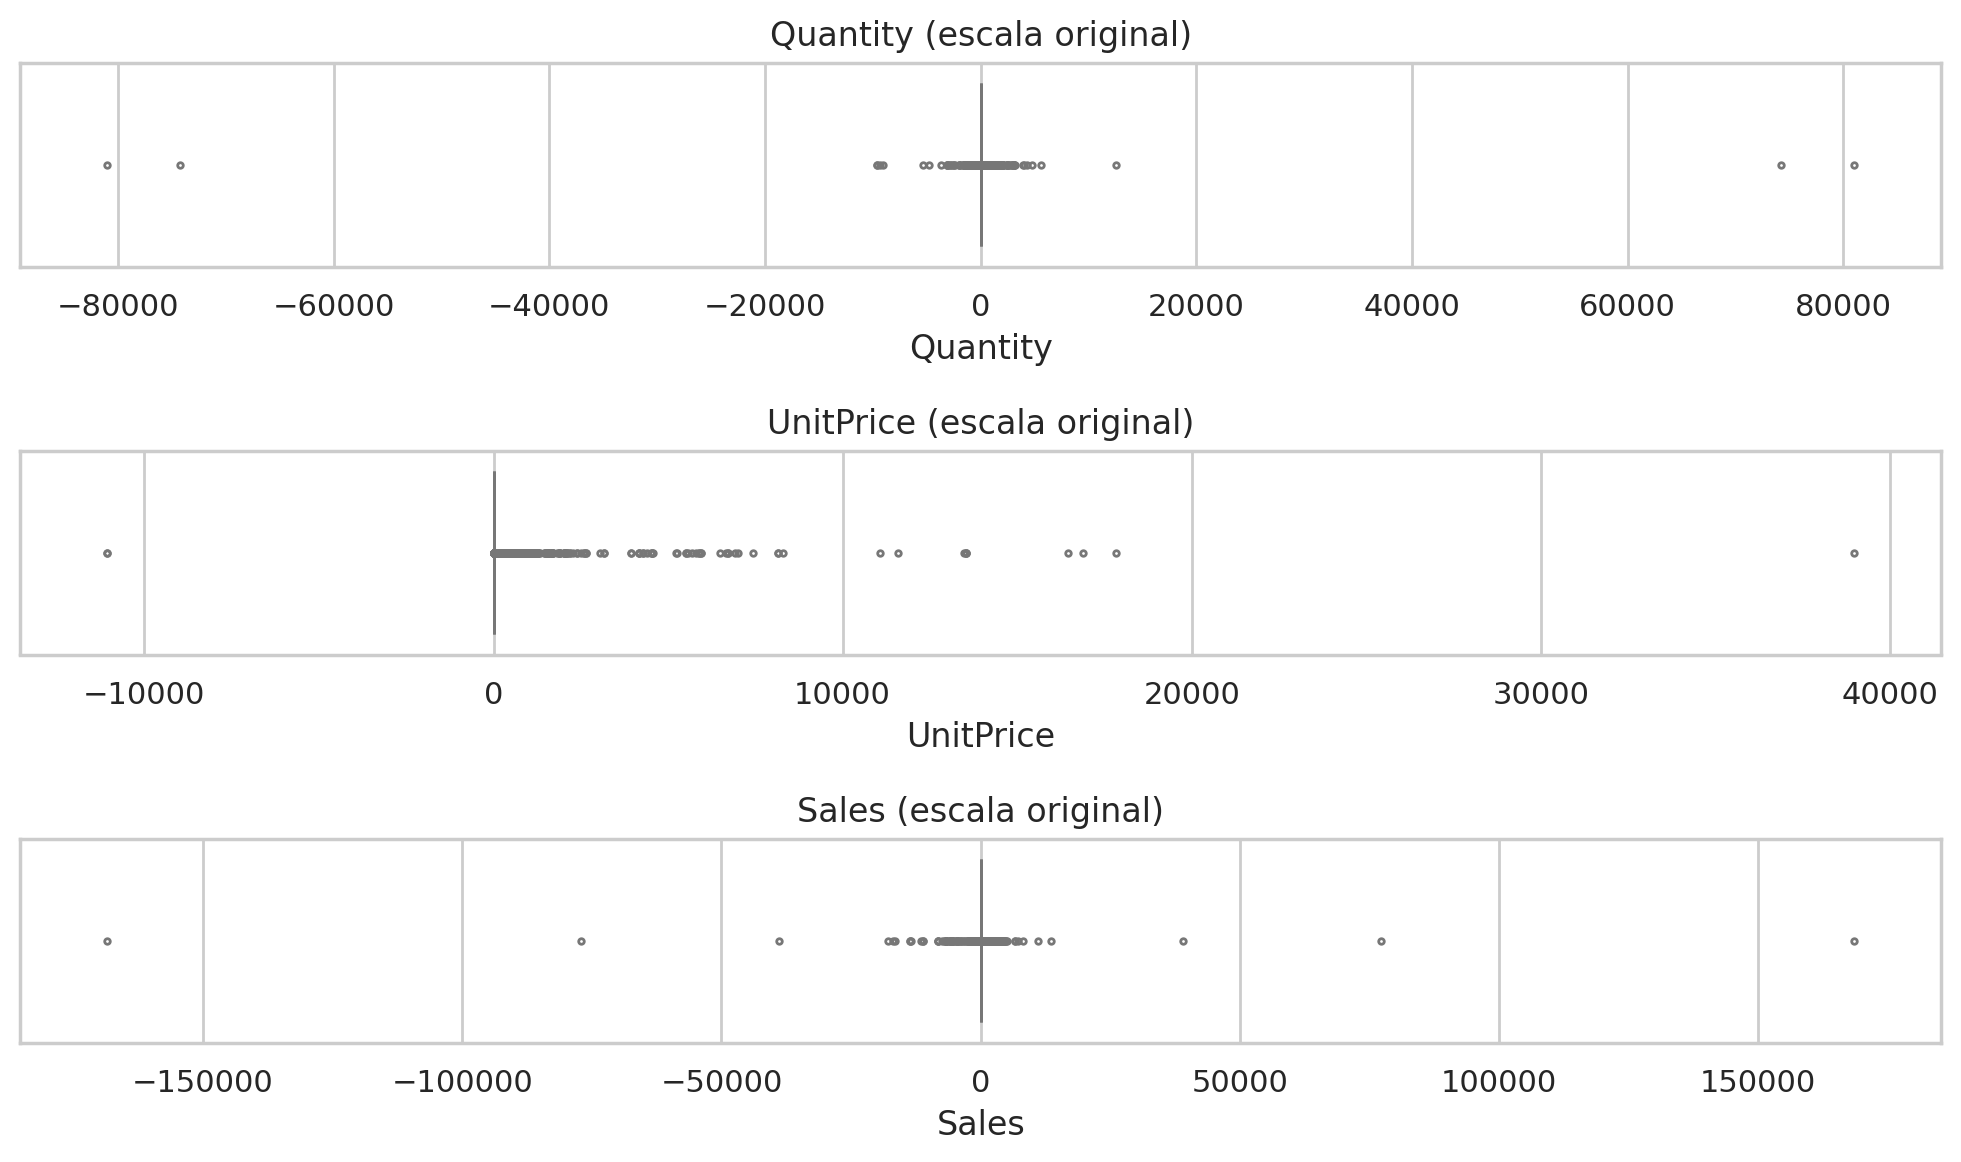

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(10, 6))
for ax, col in zip(axes, ['Quantity', 'UnitPrice', 'Sales']):
    sns.boxplot(x=df[col], ax=ax, color='lightsteelblue', fliersize=2)
    ax.set_title(f'{col} (escala original)')
plt.tight_layout(); plt.show()

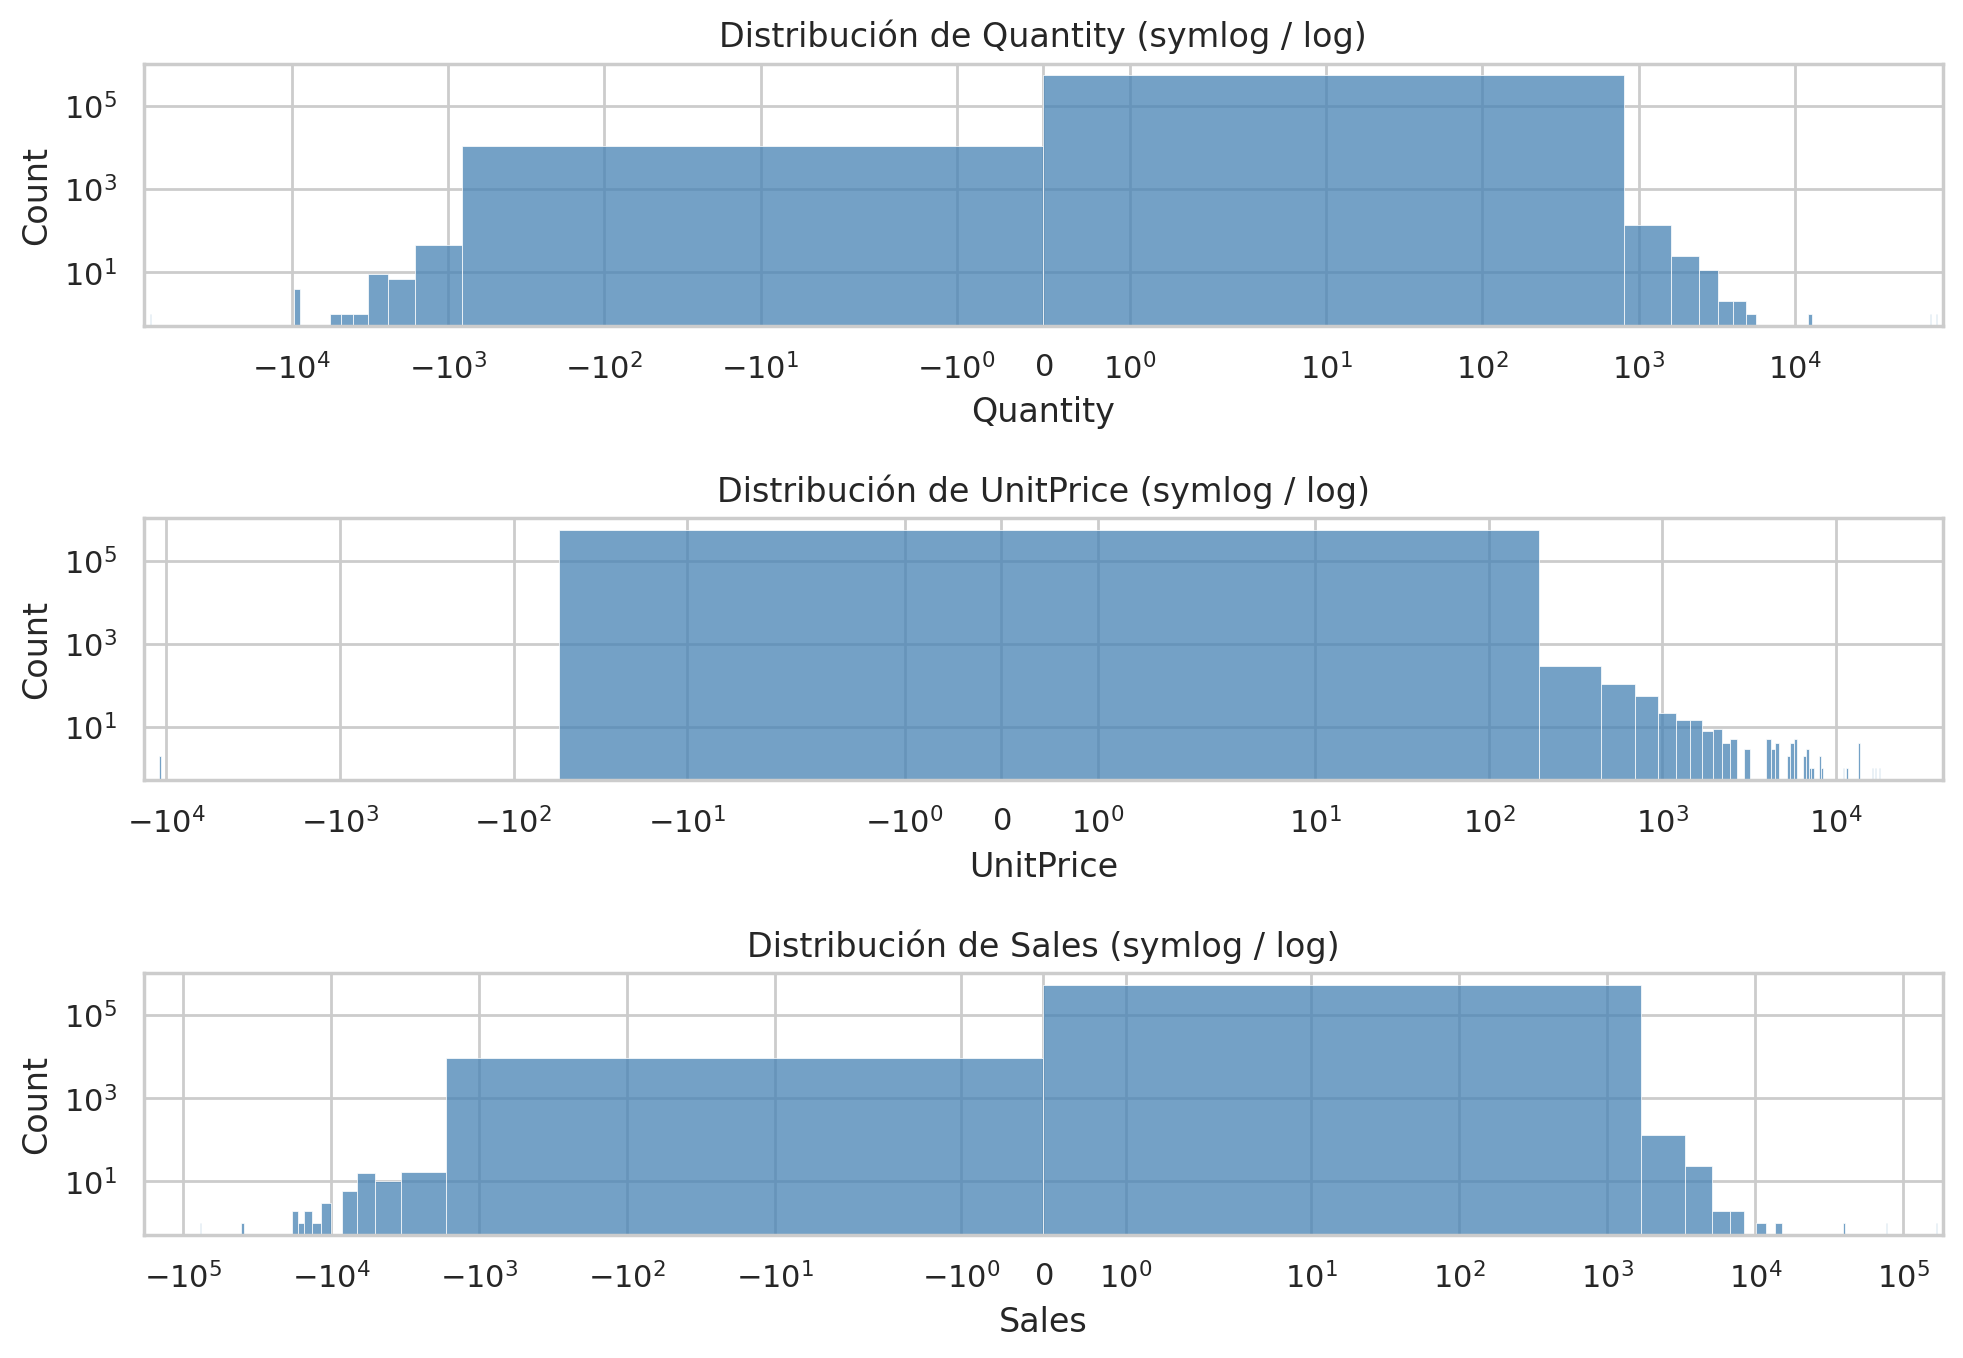

In [24]:
# Las escalas originales esconden la distribución: usamos escala simétrica logarítmica
fig, axes = plt.subplots(3, 1, figsize=(10, 7))
for ax, col in zip(axes, ['Quantity', 'UnitPrice', 'Sales']):
    sns.histplot(df[col], bins=200, ax=ax, color='steelblue')
    ax.set_xscale('symlog'); ax.set_yscale('log')
    ax.set_title(f'Distribución de {col} (symlog / log)')
plt.tight_layout(); plt.show()

In [25]:
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

pos = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
rows = []
for col in ['Quantity', 'UnitPrice', 'Sales']:
    for k in (1.5, 3):
        m = iqr_outliers(pos[col], k)
        rows.append({'columna': col, 'k (IQR)': k, 'outliers': m.sum(), '%': m.mean() * 100})
pd.DataFrame(rows)

,columna,k (IQR),outliers,%
0,Quantity,1.50,56363,10.63
1,Quantity,3.00,20511,3.87
2,UnitPrice,1.50,37999,7.17
3,UnitPrice,3.00,12204,2.30
4,Sales,1.50,42651,8.05
5,Sales,3.00,26576,5.01


El criterio IQR clásico (k=1,5) marca demasiadas filas como outliers (la distribución es muy asimétrica: muchos pedidos pequeños y algunos mayoristas grandes). La guía sugiere que al menos un 90-95% de los datos **no** sean outliers, así que será más razonable un umbral más laxo (k=3, percentil 99,9 o umbral manual) o tratar los outliers a nivel de **ventas diarias** en lugar de por línea.

In [26]:
# Transacciones más extremas
cols = ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'Sales', 'InvoiceDate', 'CustomerID']
print('Top 5 líneas por importe positivo')
display(df.nlargest(5, 'Sales')[cols])
print('Top 5 líneas por importe negativo')
display(df.nsmallest(5, 'Sales')[cols])

Top 5 líneas por importe positivo


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Sales,InvoiceDate,CustomerID
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60",2011-12-09 09:15:00,16446
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60",2011-01-18 10:01:00,12346
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00",2011-06-10 15:28:00,15098
15017,537632,AMAZONFEE,AMAZON FEE,1,"13,541.33","13,541.33",2010-12-07 15:08:00,NaN
299982,A563185,B,Adjust bad debt,1,"11,062.06","11,062.06",2011-08-12 14:50:00,NaN


Top 5 líneas por importe negativo


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Sales,InvoiceDate,CustomerID
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,"-168,469.60",2011-12-09 09:27:00,16446
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,"-77,183.60",2011-01-18 10:17:00,12346
222681,C556445,M,Manual,-1,"38,970.00","-38,970.00",2011-06-10 15:31:00,15098
524602,C580605,AMAZONFEE,AMAZON FEE,-1,"17,836.46","-17,836.46",2011-12-05 11:36:00,NaN
43702,C540117,AMAZONFEE,AMAZON FEE,-1,"16,888.02","-16,888.02",2011-01-05 09:55:00,NaN


In [27]:
# ¿Los pedidos gigantes se cancelan después? (misma cantidad, producto y cliente con signo contrario)
big = df[df['Sales'].abs() > 10_000]
big[cols].sort_values('InvoiceDate')

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Sales,InvoiceDate,CustomerID
15016,C537630,AMAZONFEE,AMAZON FEE,-1,"13,541.33","-13,541.33",2010-12-07 15:04:00,NaN
15017,537632,AMAZONFEE,AMAZON FEE,1,"13,541.33","13,541.33",2010-12-07 15:08:00,NaN
16232,C537644,AMAZONFEE,AMAZON FEE,-1,"13,474.79","-13,474.79",2010-12-07 15:34:00,NaN
16356,C537651,AMAZONFEE,AMAZON FEE,-1,"13,541.33","-13,541.33",2010-12-07 15:49:00,NaN
43702,C540117,AMAZONFEE,AMAZON FEE,-1,"16,888.02","-16,888.02",2011-01-05 09:55:00,NaN
43703,C540118,AMAZONFEE,AMAZON FEE,-1,"16,453.71","-16,453.71",2011-01-05 09:57:00,NaN
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60",2011-01-18 10:01:00,12346
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,"-77,183.60",2011-01-18 10:17:00,12346
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00",2011-06-10 15:28:00,15098
222681,C556445,M,Manual,-1,"38,970.00","-38,970.00",2011-06-10 15:31:00,15098


**Hallazgos sobre outliers**

- Los dos pedidos más grandes (80.995 uds. de *PAPER CRAFT, LITTLE BIRDIE* y 74.215 uds. de *MEDIUM CERAMIC TOP STORAGE JAR*) **fueron cancelados** con una factura `C` por la misma cantidad → se compensan, pero distorsionan el total diario de esos días si no se tratan juntos.
- Lo mismo ocurre con *PICNIC BASKET WICKER 60 PIECES* (£38.970), anulado minutos después con un ajuste manual (`C556445`, código `M`).
- Los mayores importes por precio unitario provienen de **códigos especiales** (`AMAZONFEE`, `M`, `DOT`, `POST`, `B`) y no de productos.

## 5. Análisis temporal

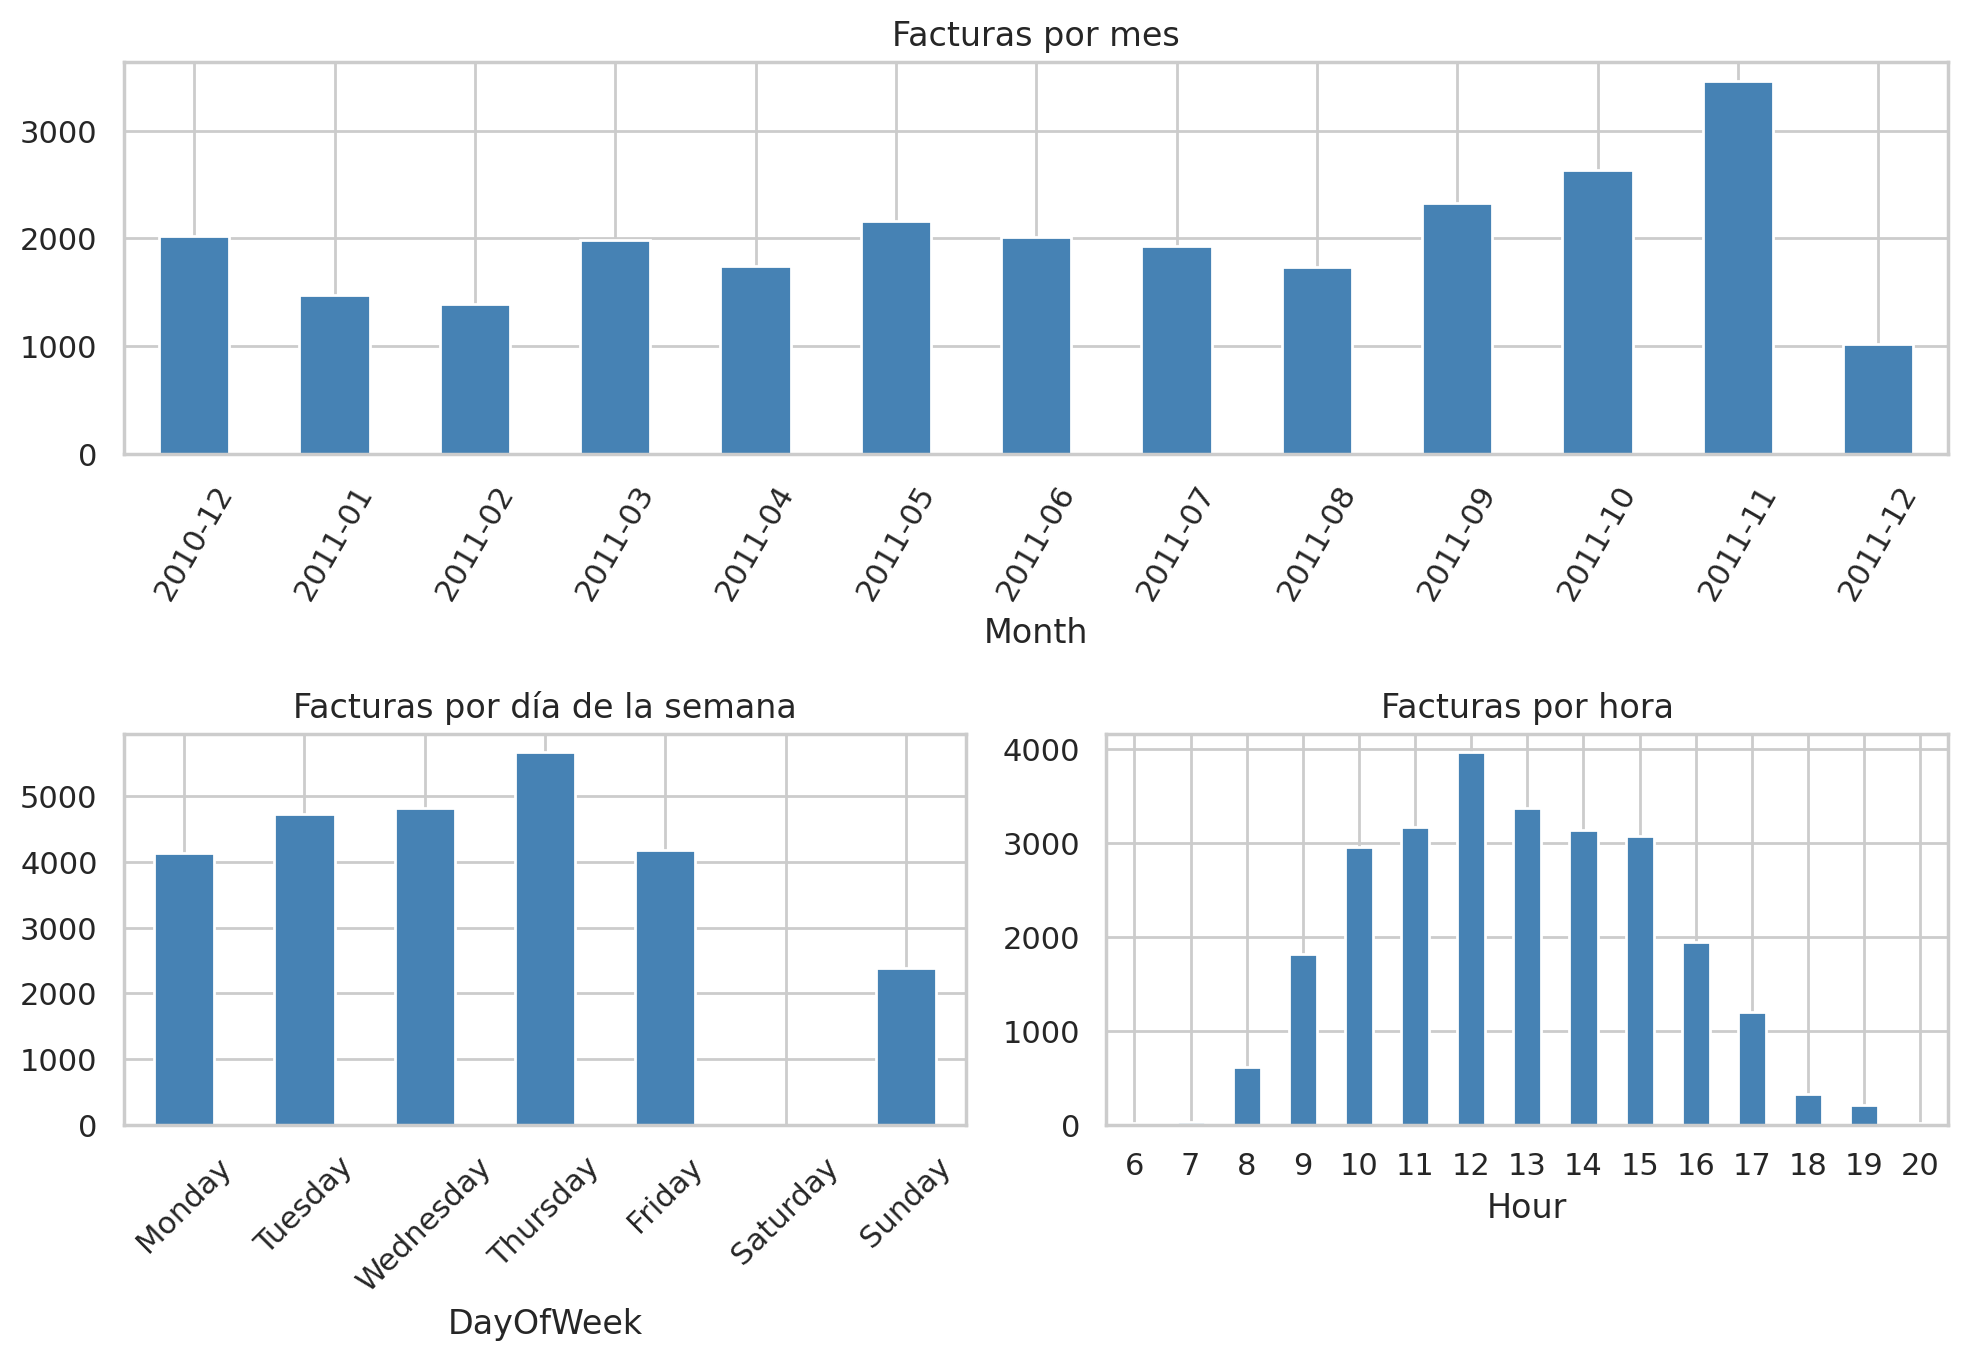

In [28]:
df['Date'] = df['InvoiceDate'].dt.normalize()
df['Hour'] = df['InvoiceDate'].dt.hour
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Month'] = df['InvoiceDate'].dt.to_period('M')

dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
fig, axes = plt.subplot_mosaic([['mes', 'mes'], ['dia', 'hora']], figsize=(10, 7))
df.groupby('Month')['InvoiceNo'].nunique().plot.bar(ax=axes['mes'], color='steelblue', rot=60)
axes['mes'].set_title('Facturas por mes')
df.groupby('DayOfWeek')['InvoiceNo'].nunique().reindex(dow_order).plot.bar(ax=axes['dia'], color='steelblue', rot=45)
axes['dia'].set_title('Facturas por día de la semana')
df.groupby('Hour')['InvoiceNo'].nunique().plot.bar(ax=axes['hora'], color='steelblue', rot=0)
axes['hora'].set_title('Facturas por hora')
plt.tight_layout(); plt.show()

In [29]:
all_days = pd.date_range(df['Date'].min(), df['Date'].max(), freq='D')
missing_days = all_days.difference(df['Date'].unique())
print(f'Días en el rango: {len(all_days)} | días con ventas: {df["Date"].nunique()} | días sin datos: {len(missing_days)}')
print('Días de la semana sin datos:')
print(pd.Series(missing_days.day_name()).value_counts())
print('\nDías sin datos que NO son sábado:')
print([d.strftime('%Y-%m-%d (%a)') for d in missing_days if d.dayofweek != 5])

Días en el rango: 374 | días con ventas: 305 | días sin datos: 69
Días de la semana sin datos:
Saturday     53
Monday        6
Friday        4
Sunday        3
Tuesday       1
Wednesday     1
Thursday      1
Name: count, dtype: int64

Días sin datos que NO son sábado:
['2010-12-24 (Fri)', '2010-12-26 (Sun)', '2010-12-27 (Mon)', '2010-12-28 (Tue)', '2010-12-29 (Wed)', '2010-12-30 (Thu)', '2010-12-31 (Fri)', '2011-01-02 (Sun)', '2011-01-03 (Mon)', '2011-04-22 (Fri)', '2011-04-24 (Sun)', '2011-04-25 (Mon)', '2011-04-29 (Fri)', '2011-05-02 (Mon)', '2011-05-30 (Mon)', '2011-08-29 (Mon)']


- **No hay ventas ningún sábado**: la tienda no opera ese día. Habrá que decidir si incluir los sábados con ventas 0 o excluirlos de la serie.
- Hay un **parón navideño** (24/12/2010 a 03/01/2011) y algunos festivos (Semana Santa, boda real 29/04, bank holidays de mayo/agosto). Los domingos sí hay ventas.
- La actividad crece claramente en **septiembre-noviembre** (campaña de Navidad), que coincide con el periodo de test.
- Las compras se concentran entre las 10 y las 15 h.

## 6. Variable objetivo: ventas diarias

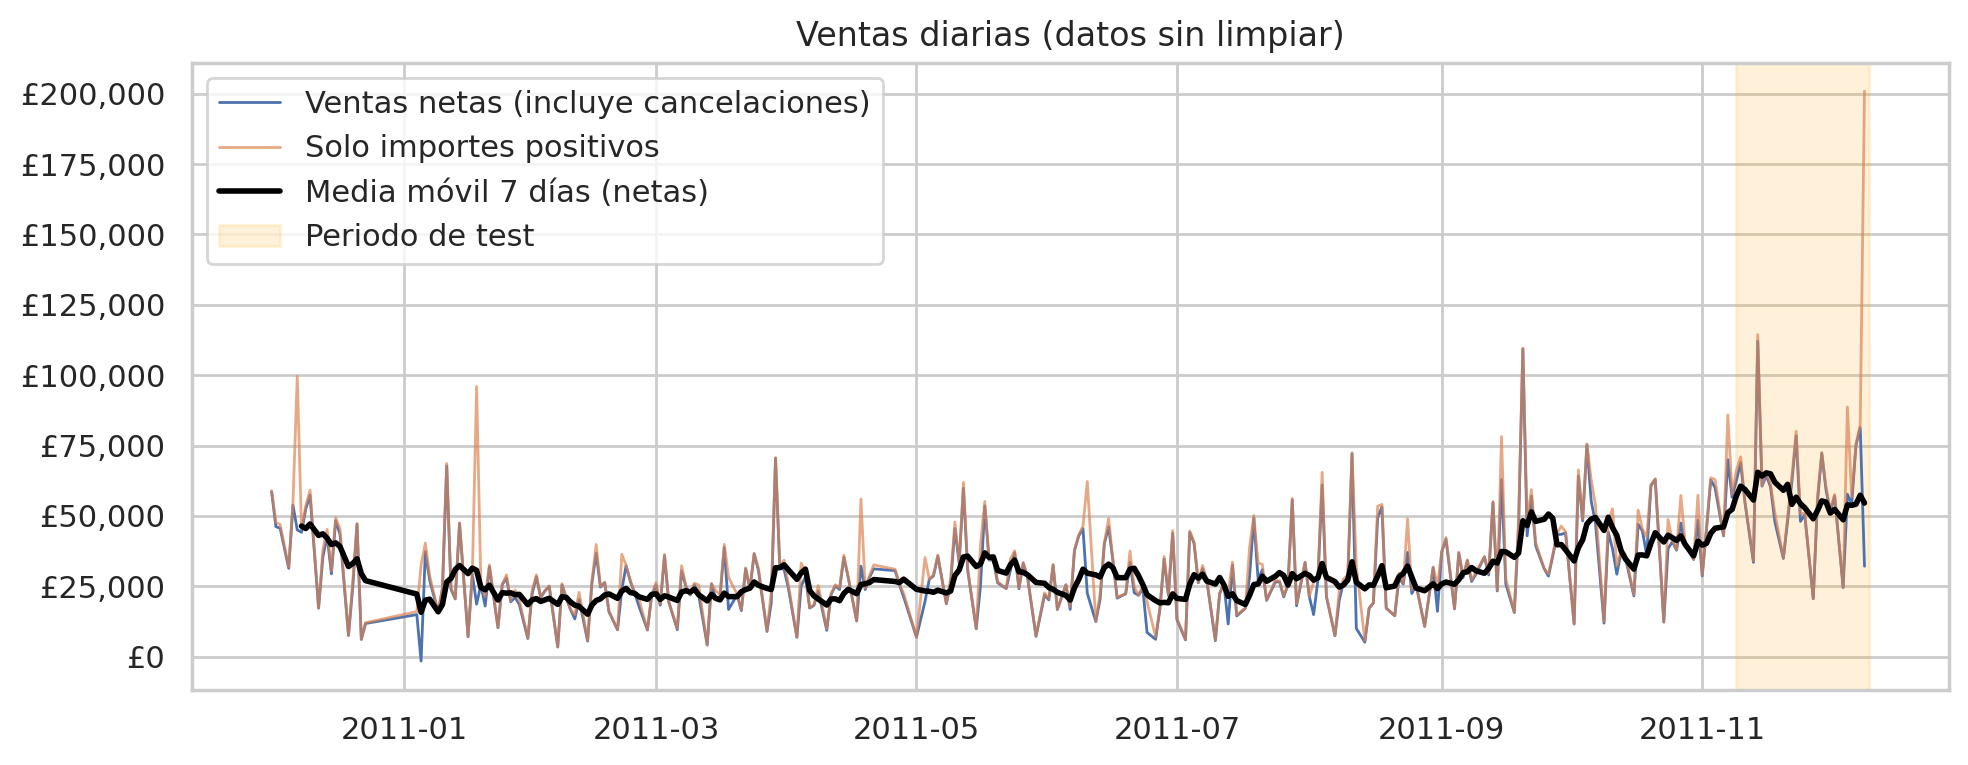

In [30]:
# Vista preliminar SIN limpieza: suma de Quantity*UnitPrice por día
daily = df.groupby('Date')['Sales'].sum()
daily_pos = df[df['Sales'] > 0].groupby('Date')['Sales'].sum()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily.values, label='Ventas netas (incluye cancelaciones)', lw=1)
ax.plot(daily_pos.index, daily_pos.values, label='Solo importes positivos', lw=1, alpha=.7)
ax.plot(daily.index, daily.rolling(7).mean(), label='Media móvil 7 días (netas)', lw=2, color='black')
ax.axvspan(TEST_START, TEST_END + pd.Timedelta(days=1), color='orange', alpha=.15, label='Periodo de test')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))
ax.set_title('Ventas diarias (datos sin limpiar)'); ax.legend()
plt.tight_layout(); plt.show()

In [31]:
daily.describe(percentiles=[.01, .05, .5, .95, .99]).to_frame('ventas netas diarias')

,ventas netas diarias
count,305.00
mean,"31,959.83"
std,"17,414.26"
min,"-1,566.23"
1%,"5,165.59"
5%,"7,737.82"
50%,"27,978.41"
95%,"62,918.36"
99%,"78,351.25"
max,"112,141.11"


In [32]:
print('Días con ventas netas más altas:')
display(daily.nlargest(5).to_frame('ventas'))
print('Días con ventas netas más bajas:')
display(daily.nsmallest(5).to_frame('ventas'))

Días con ventas netas más altas:


,ventas
Date,
2011-11-14,"112,141.11"
2011-09-20,"109,286.21"
2011-12-08,"81,417.78"
2011-11-23,"78,480.70"
2011-10-05,"75,244.43"


Días con ventas netas más bajas:


,ventas
Date,
2011-01-05,"-1,566.23"
2011-02-06,"3,457.11"
2011-03-13,"4,137.62"
2011-08-14,"5,150.18"
2011-02-13,"5,535.40"


- La mediana de ventas netas diarias es ~£28k y el 80% de los días está entre ~£12k y ~£57k, con los valores más altos en sept.-dic.
- El 05/01/2011 tiene **ventas netas negativas**: ese día se cancelaron varios cargos `AMAZONFEE` de importe muy alto. Es un ejemplo claro de por qué los códigos especiales y las cancelaciones deben tratarse antes de construir la serie.

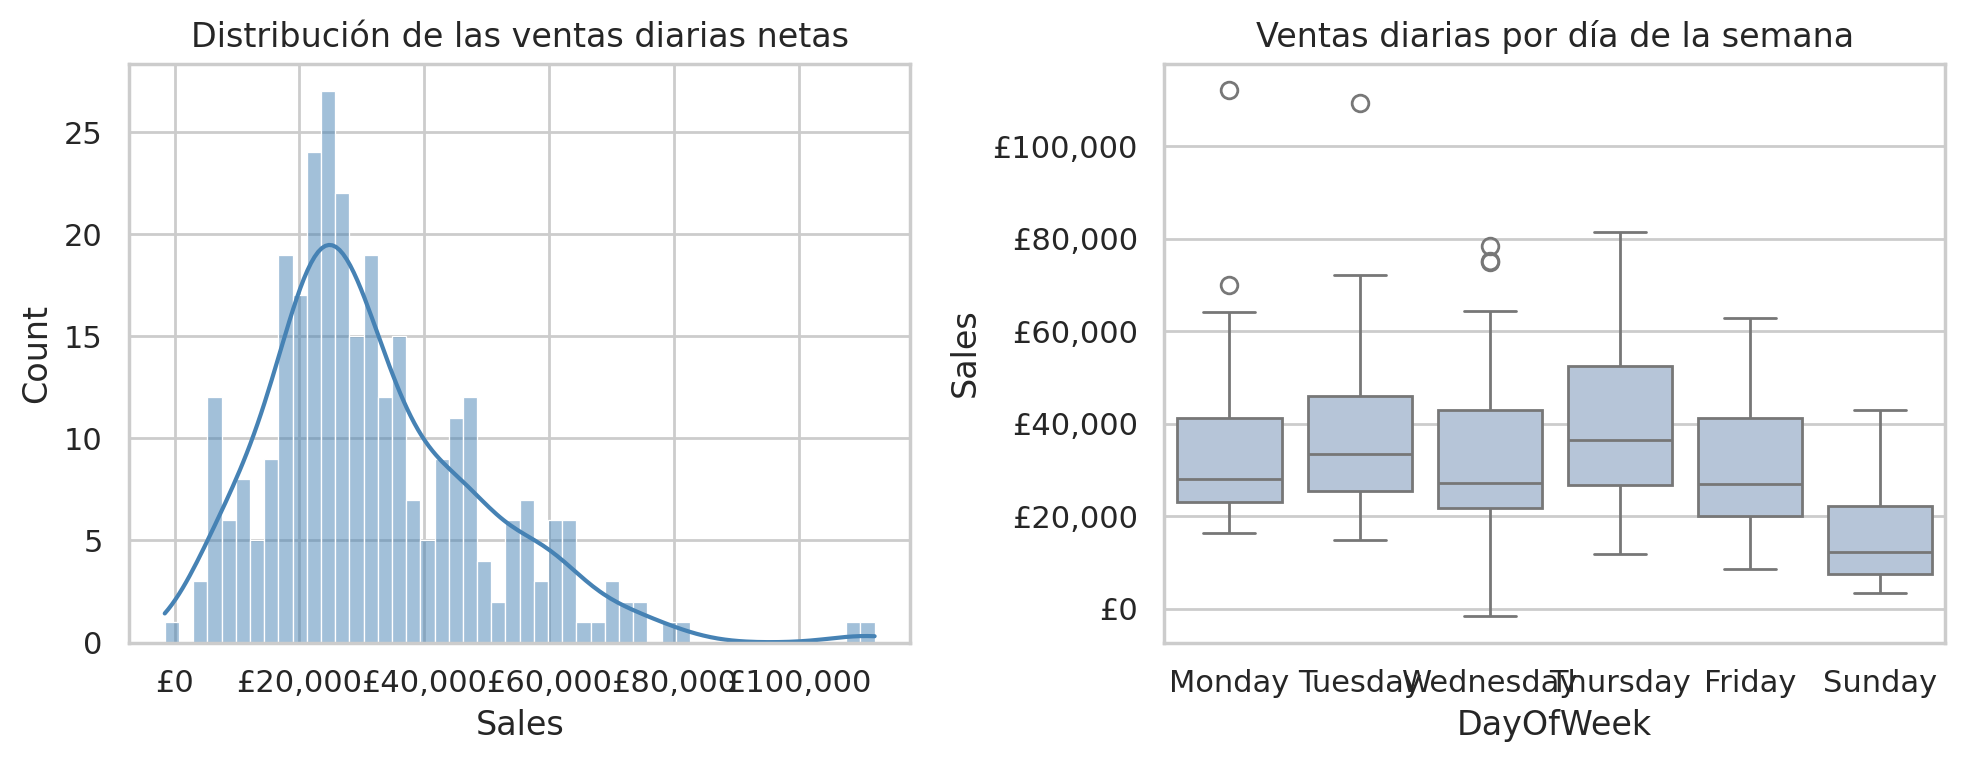

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(daily, bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribución de las ventas diarias netas')
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))

daily_df = daily.to_frame('Sales')
daily_df['DayOfWeek'] = daily_df.index.day_name()
sns.boxplot(data=daily_df, x='DayOfWeek', y='Sales', order=[d for d in dow_order if d != 'Saturday'], ax=axes[1], color='lightsteelblue')
axes[1].set_title('Ventas diarias por día de la semana')
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))
plt.tight_layout(); plt.show()

In [34]:
# Volumen de cada partición según el enunciado
split = pd.cut(df['Date'],
               bins=[TRAIN_START - pd.Timedelta(days=1), TEST_START - pd.Timedelta(days=1), TEST_END],
               labels=['train + validación', 'test'])
pd.DataFrame({
    'filas': df.groupby(split, observed=True).size(),
    'días con ventas': df.groupby(split, observed=True)['Date'].nunique(),
    'ventas netas (£)': df.groupby(split, observed=True)['Sales'].sum(),
})

,filas,días con ventas,ventas netas (£)
Date,,,
train + validación,451127,278,"8,218,763.73"
test,90782,27,"1,528,984.20"


## 7. Limpieza de datos

A partir de los hallazgos del EDA aplicamos las siguientes decisiones. Partimos de las columnas originales para que la limpieza sea reproducible e independiente de las columnas auxiliares creadas durante el análisis.

| Paso | Decisión | Justificación |
|---|---|---|
| 1 | Eliminar filas sin `Description` | Todas tienen precio 0 y ningún cliente: no son ventas |
| 2 | Eliminar duplicados exactos | Errores de registro; inflarían artificialmente las ventas |
| 3 | Eliminar `UnitPrice <= 0` | No generan ingresos (ajustes de stock, regalos) o son ajustes de deuda |
| 4 | Eliminar `Quantity < 0` que no son cancelación | Ajustes de inventario sin precio (en la práctica ya los elimina el paso 3, porque todos tienen `UnitPrice = 0`; se deja como comprobación explícita) |
| 5 | Excluir códigos contables (`AMAZONFEE`, `BANK CHARGES`, `CRUK`, `B`, `M`, `m`, `S`) | Comisiones, ajustes y muestras: no son ventas a clientes |
| 6 | Eliminar los pedidos extremos que se cancelaron (y su cancelación) | Se compensan entre sí, pero si caen en días distintos o se limpian por separado distorsionan la serie |
| — | **Mantener** filas sin `CustomerID` | Son ~15% del importe; para predecir ventas totales el cliente no es necesario |
| — | **Mantener** el resto de cancelaciones (`C...`) como importe negativo | El objetivo son los ingresos netos del día: una devolución reduce lo que la empresa ingresa |
| — | **Mantener** portes (`POST`, `DOT`, `C2`), descuentos (`D`) y vales regalo | Forman parte de lo que paga el cliente |

In [35]:
clean = df[['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
            'UnitPrice', 'CustomerID', 'Country']].copy()
log = [('Dataset original', len(clean))]

def step(name, mask_to_drop):
    global clean
    clean = clean[~mask_to_drop]
    log.append((name, len(clean)))

step('1. Sin Description',               clean['Description'].isnull())
step('2. Duplicados exactos',            clean.duplicated())
step('3. UnitPrice <= 0',                clean['UnitPrice'] <= 0)
step('4. Quantity < 0 sin cancelación',  (clean['Quantity'] < 0) & ~clean['InvoiceNo'].str.startswith('C'))

NON_SALES_CODES = ['AMAZONFEE', 'BANK CHARGES', 'CRUK', 'B', 'M', 'm', 'S']
step('5. Códigos contables',             clean['StockCode'].isin(NON_SALES_CODES))

# 6. Pedidos extremos cancelados (identificados en la sección 4). La cancelación del
#    PICNIC BASKET (C556445) usaba el código M y ya se ha eliminado en el paso 5.
EXTREME_INVOICES = ['581483', 'C581484', '541431', 'C541433', '556444']
step('6. Pedidos extremos cancelados',   clean['InvoiceNo'].isin(EXTREME_INVOICES))

cleaning_log = pd.DataFrame(log, columns=['paso', 'filas restantes'])
cleaning_log['filas eliminadas'] = (-cleaning_log['filas restantes'].diff()).fillna(0).astype(int)
cleaning_log['% del original'] = cleaning_log['filas restantes'] / len(df) * 100
cleaning_log

,paso,filas restantes,filas eliminadas,% del original
0,Dataset original,541909,0,100.00
1,1. Sin Description,540455,1454,99.73
2,2. Duplicados exactos,535187,5268,98.76
3,3. UnitPrice <= 0,534129,1058,98.56
4,4. Quantity < 0 sin cancelación,534129,0,98.56
5,5. Códigos contables,533418,711,98.43
6,6. Pedidos extremos cancelados,533413,5,98.43


### 7.1. Efecto de la limpieza (Sweetviz)

Comparamos el dataset original con el limpio. El informe muestra, variable a variable, cómo cambia cada distribución.

Report eda_reports/combinado/sweetviz/html/4_sweetviz_original_vs_limpio.html was generated.


Informe: [eda_reports/combinado/sweetviz/html/4_sweetviz_original_vs_limpio.html](eda_reports/combinado/sweetviz/html/4_sweetviz_original_vs_limpio.html)


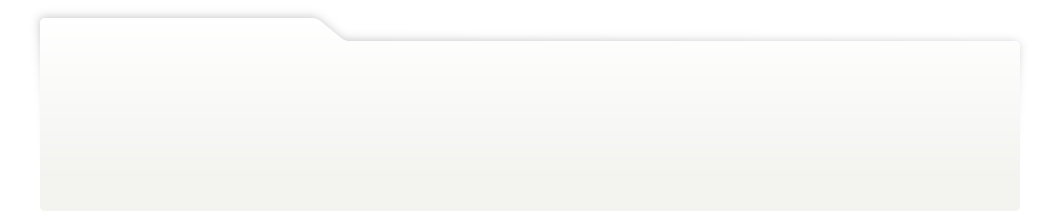
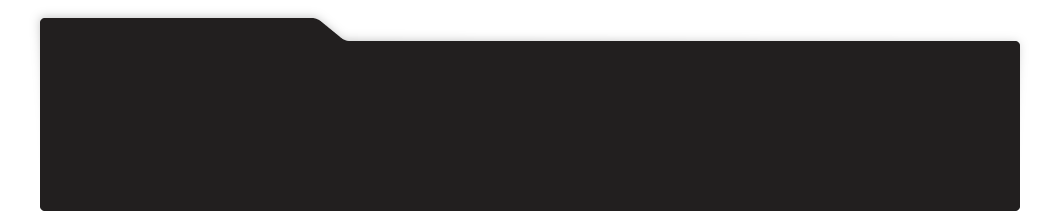
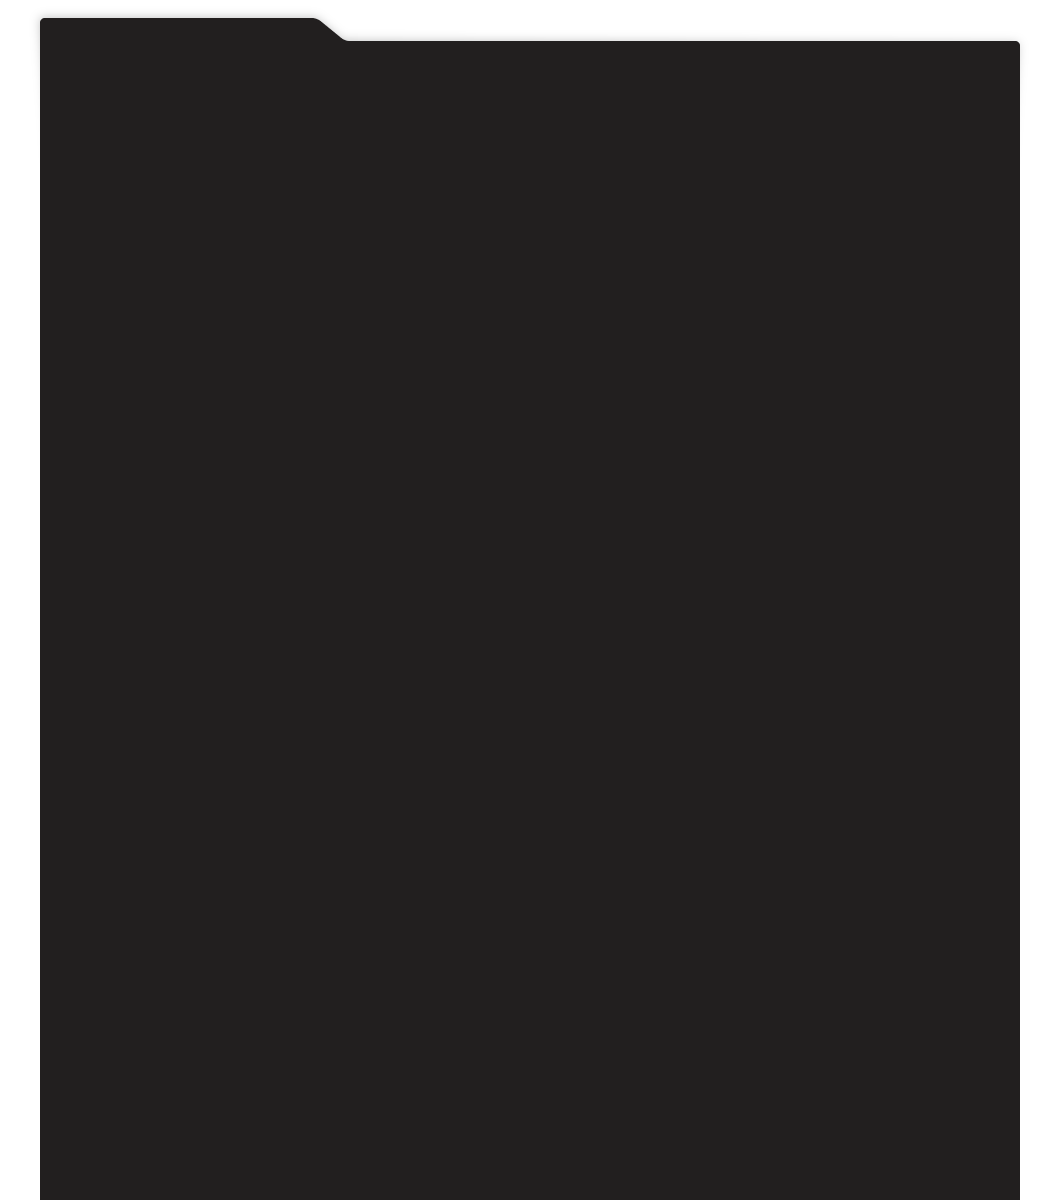
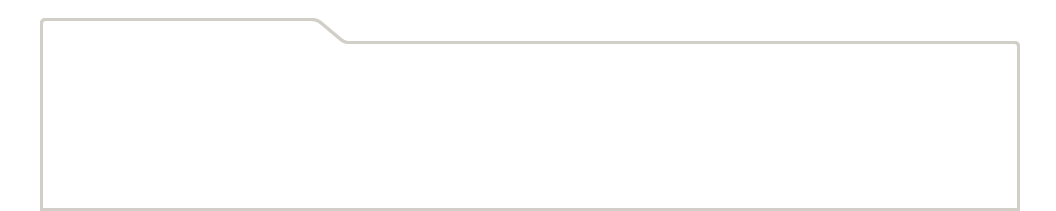
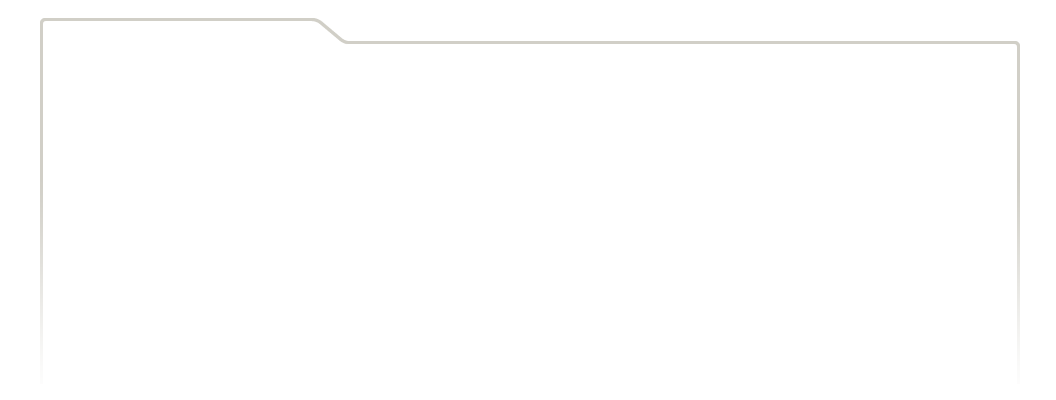
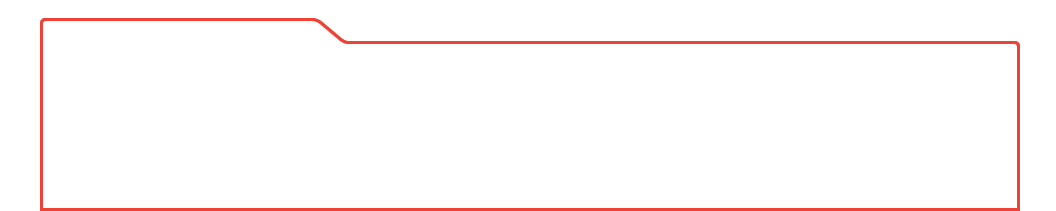
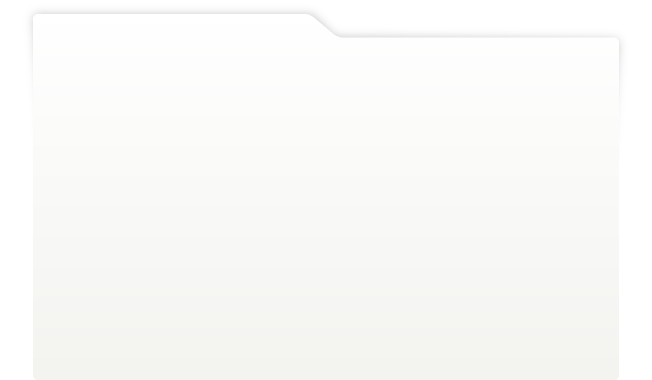
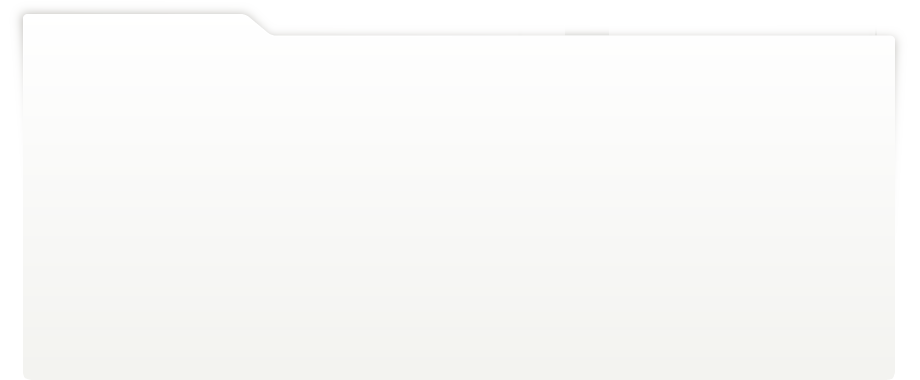
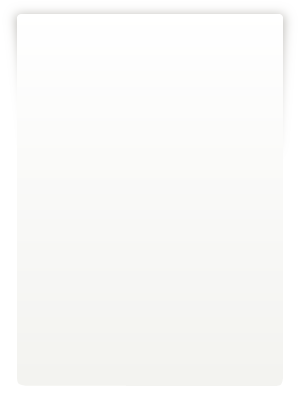
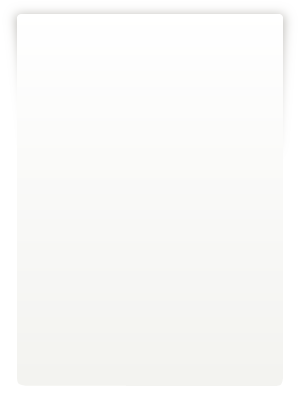
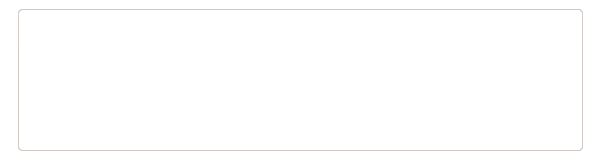
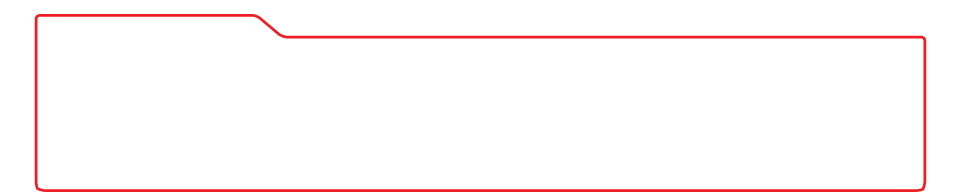
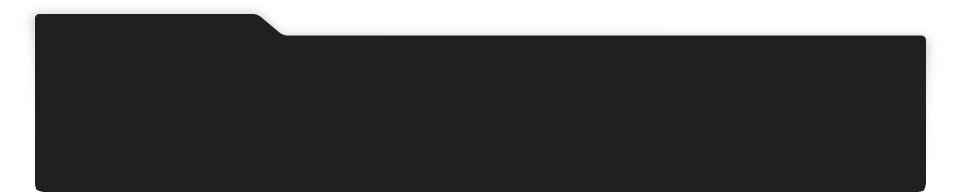
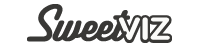
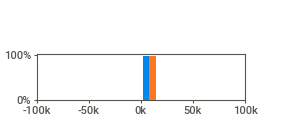
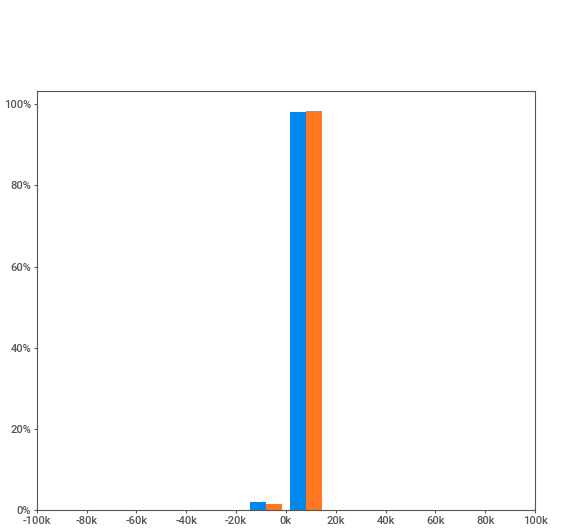
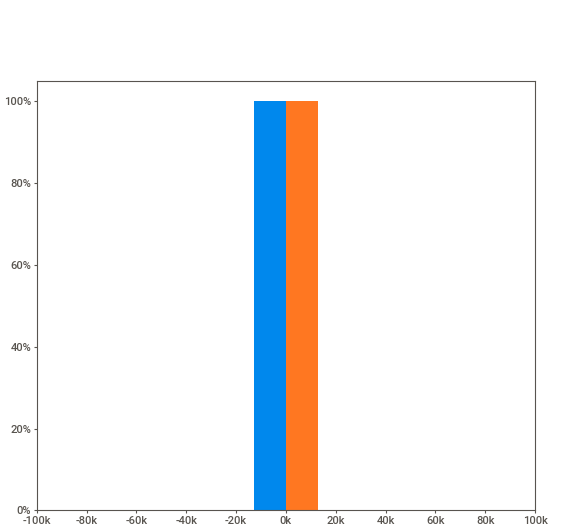
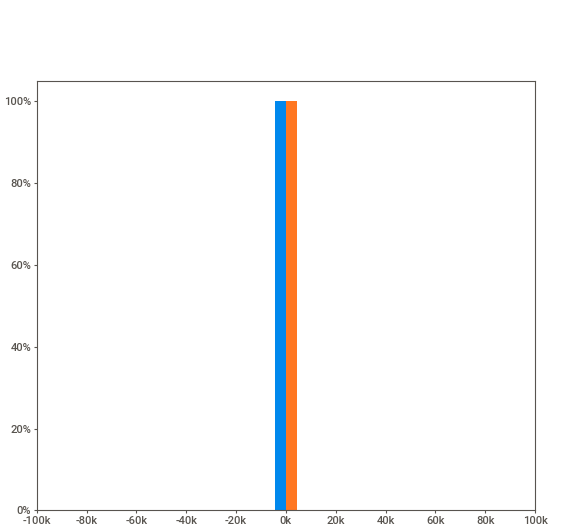
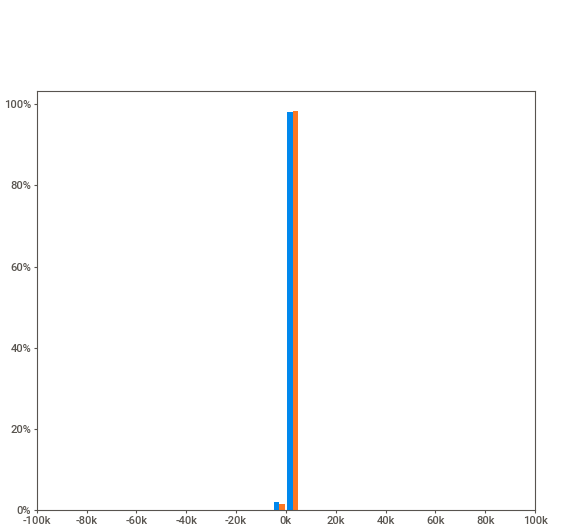
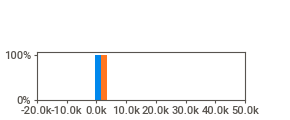
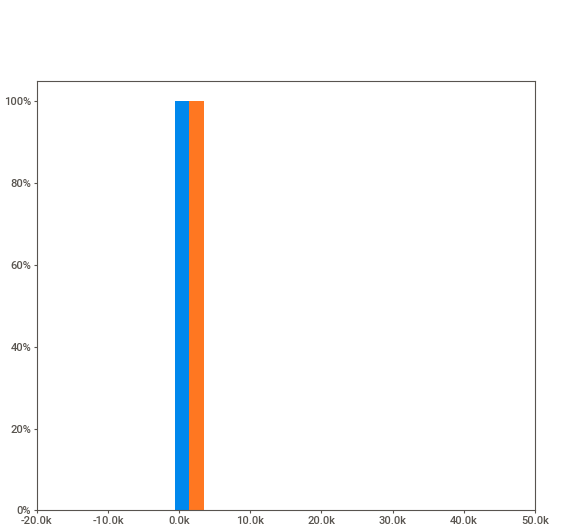
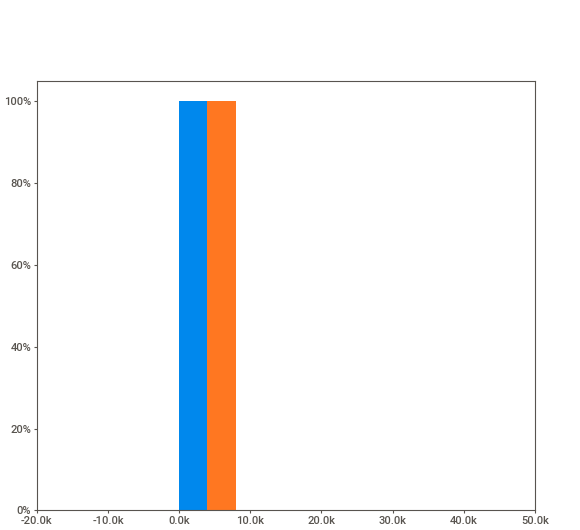
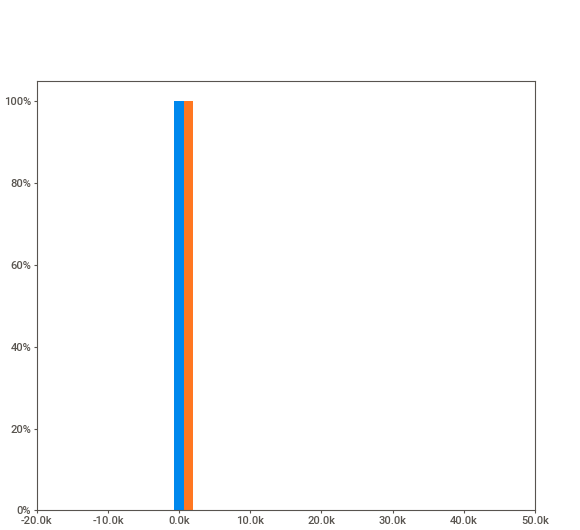
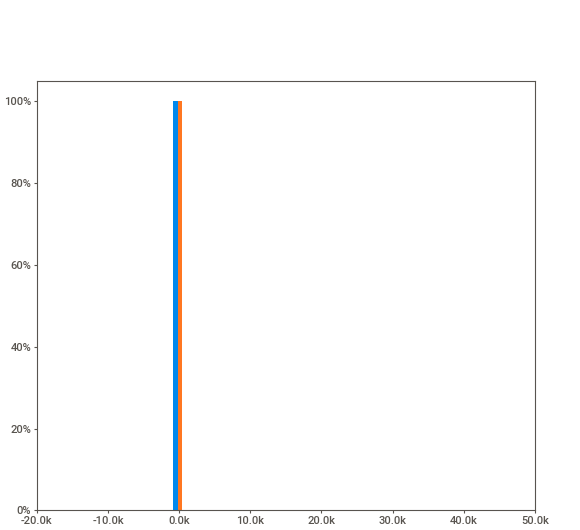
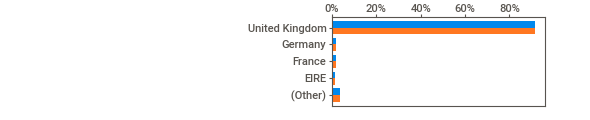
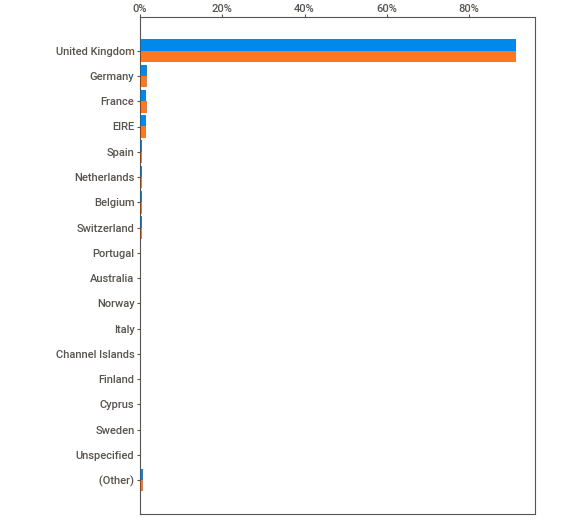
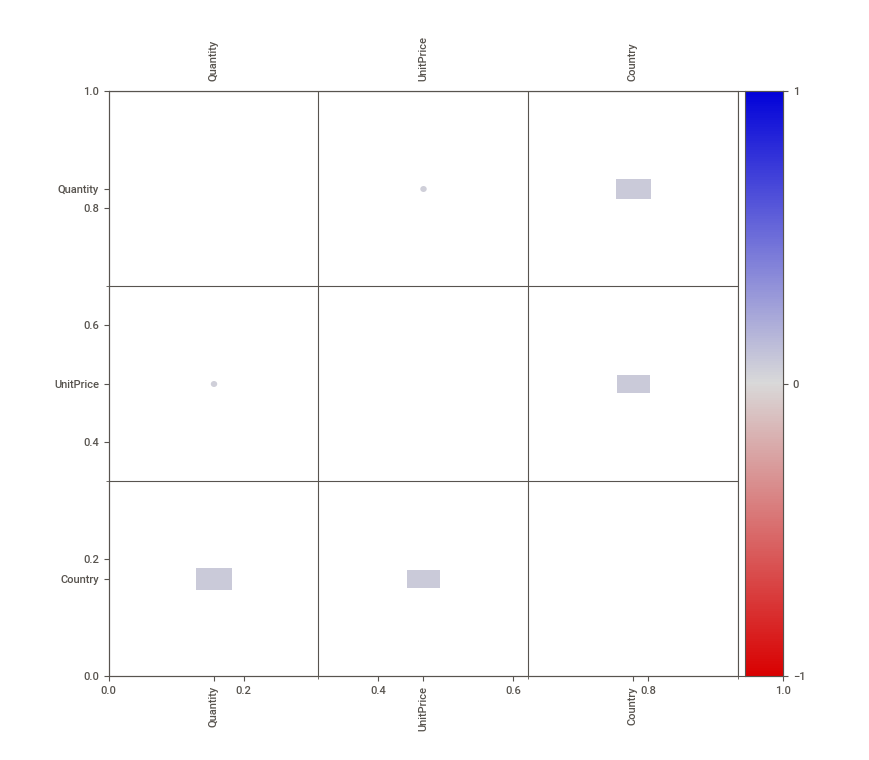
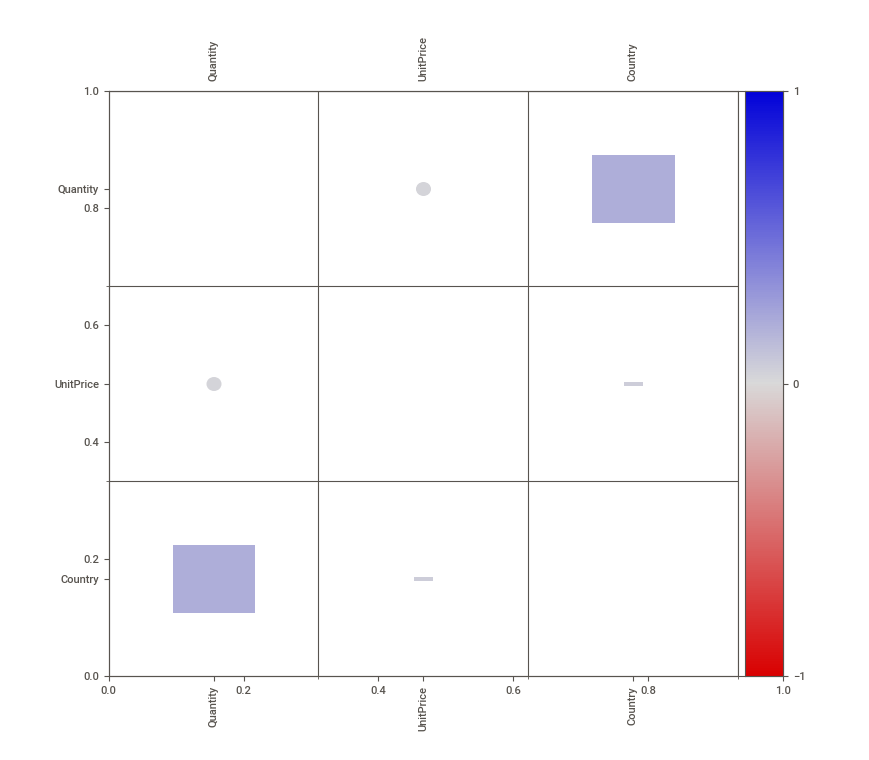

In [36]:
import sweetviz as sv

raw = df[['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']]

cmp_clean = sv.compare([raw, 'Original'], [clean, 'Limpio'])
report = report_file('sweetviz', '4_sweetviz_original_vs_limpio.html')
cmp_clean.show_html(str(report), open_browser=False, layout='vertical')
show_report(report)

In [37]:
clean['Sales'] = clean['Quantity'] * clean['UnitPrice']
raw_sales = (df['Quantity'] * df['UnitPrice']).sum()

print(f'Filas conservadas: {len(clean):,} de {len(df):,} ({len(clean) / len(df):.1%})')
print(f'Importe neto conservado: £{clean["Sales"].sum():,.0f} de £{raw_sales:,.0f}')
clean[['Quantity', 'UnitPrice', 'Sales']].describe(percentiles=[.01, .5, .99]).T

Filas conservadas: 533,413 de 541,909 (98.4%)
Importe neto conservado: £10,006,800 de £9,747,748


,count,mean,std,min,1%,50%,99%,max
Quantity,"533,413.00",9.92,40.62,"-9,360.00",-1.00,3.00,100.00,"4,800.00"
UnitPrice,"533,413.00",3.78,23.62,0.00,0.29,2.10,16.98,"8,142.75"
Sales,"533,413.00",18.76,71.36,"-8,142.75",-5.90,9.90,180.00,"8,142.75"


Se conserva el **98,4% de las filas**, por encima del 90-95% que recomienda la guía. El importe neto conservado (≈£10,0M) es incluso **mayor** que el bruto (≈£9,75M) porque los códigos contables eliminados (comisiones de Amazon, ajustes manuales, cargos bancarios…) eran mayoritariamente negativos. Las líneas individuales grandes que quedan (mayoristas que compran miles de unidades) son ventas reales; los outliers se tratan a nivel de **ventas diarias**, que es la variable a predecir.

### 7.2. Periodo de entrenamiento/validación vs. periodo de test (Sweetviz)

Comparamos ambos periodos sobre los datos limpios para ver qué cambia.

Report eda_reports/combinado/sweetviz/html/4_sweetviz_train_vs_test.html was generated.


Informe: [eda_reports/combinado/sweetviz/html/4_sweetviz_train_vs_test.html](eda_reports/combinado/sweetviz/html/4_sweetviz_train_vs_test.html)


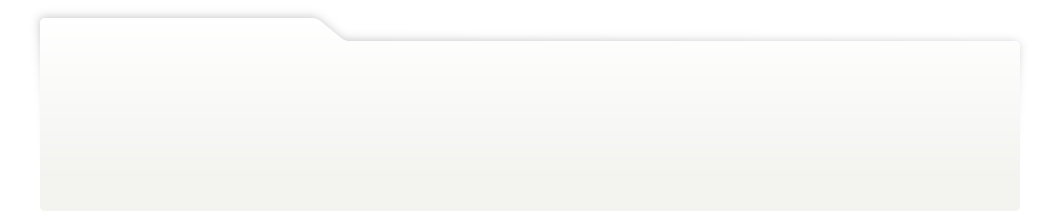
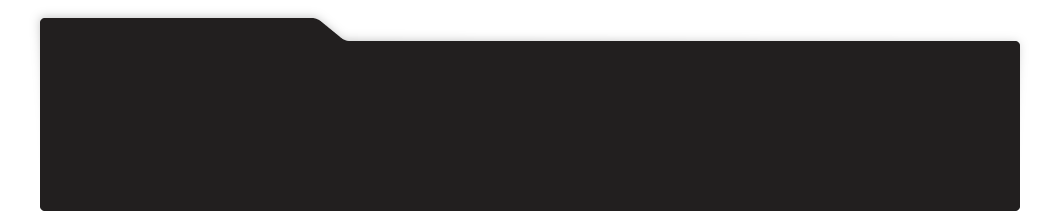
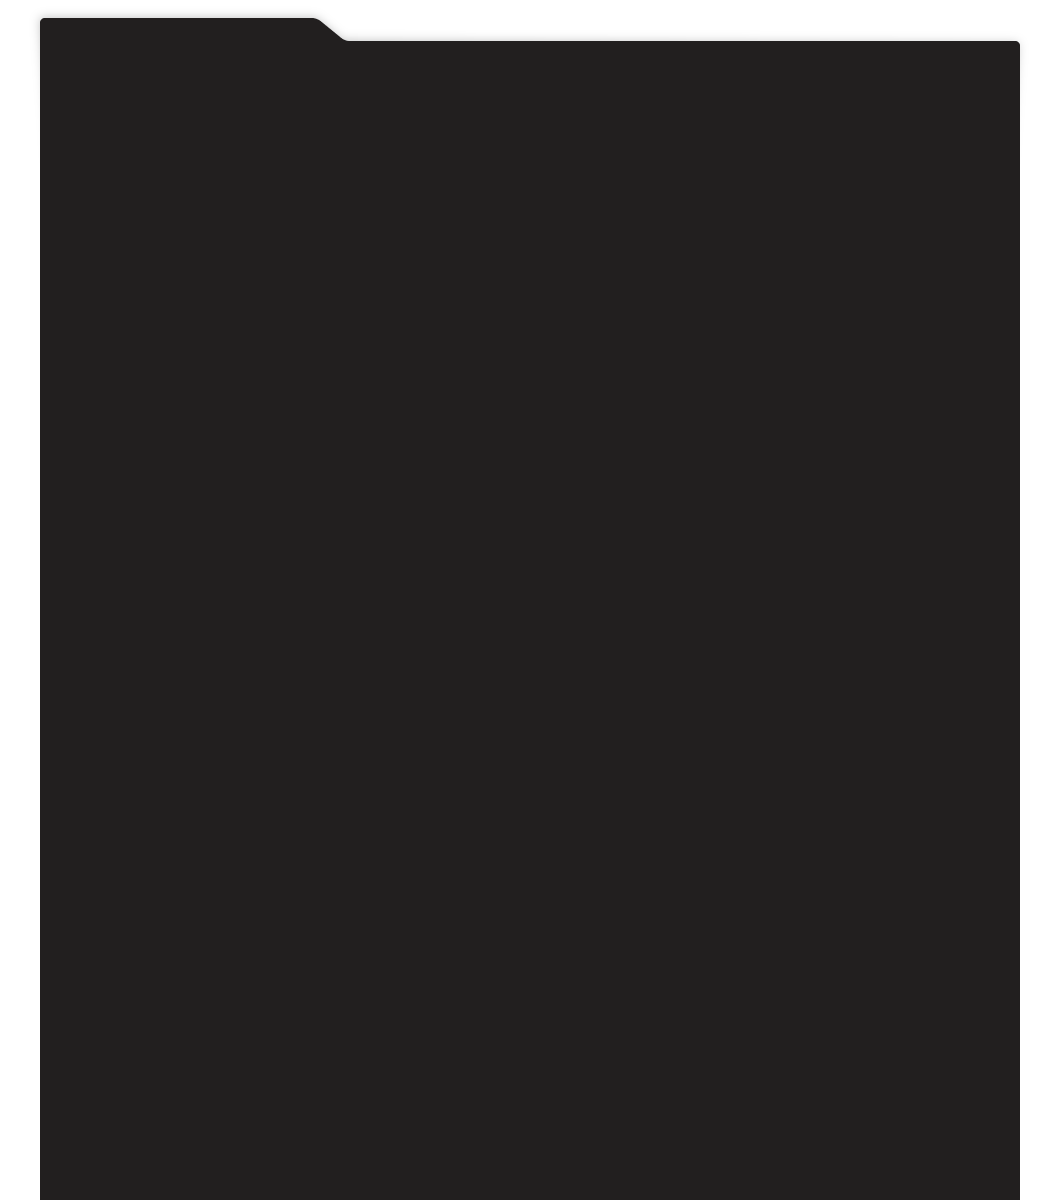
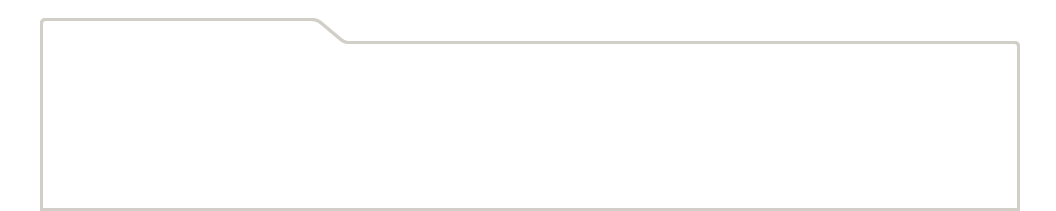
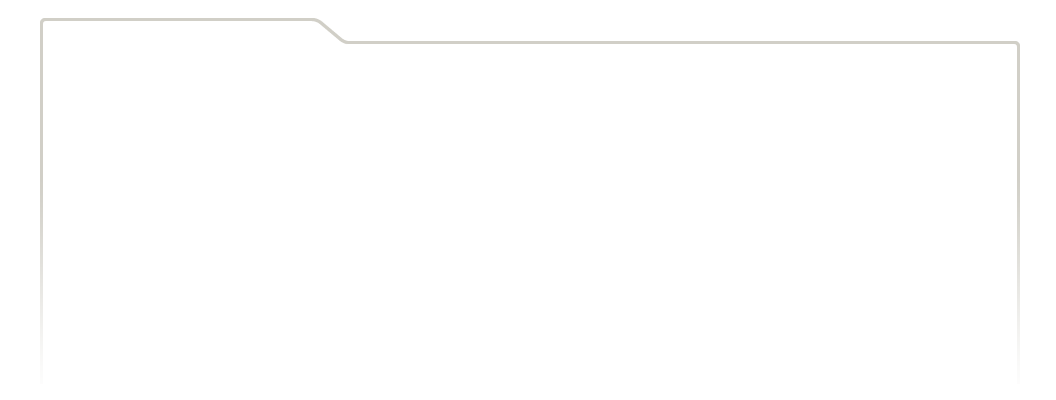
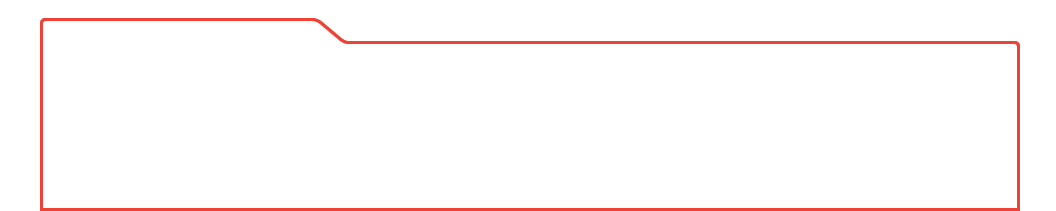
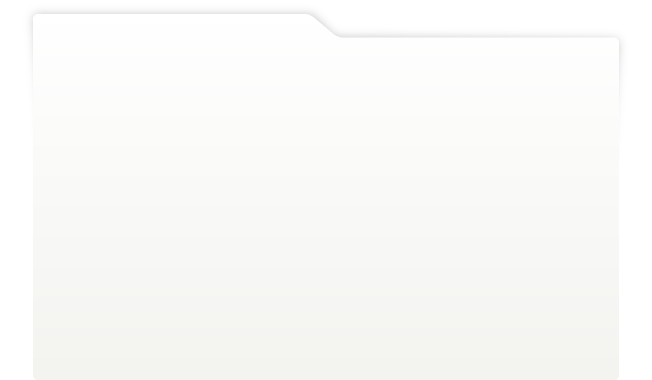
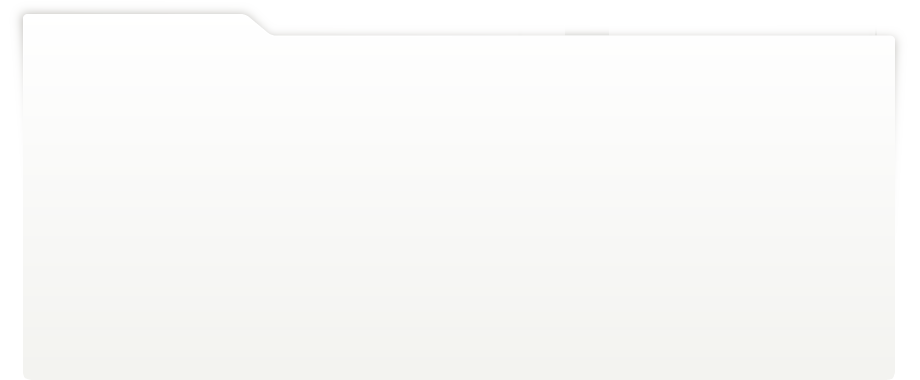
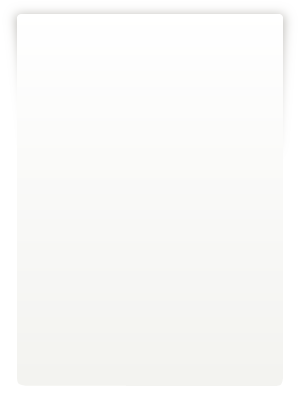
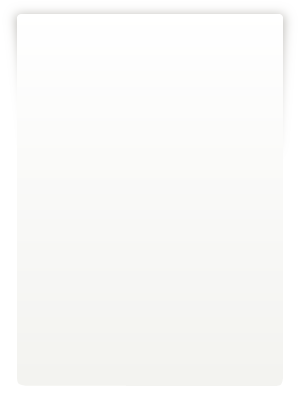
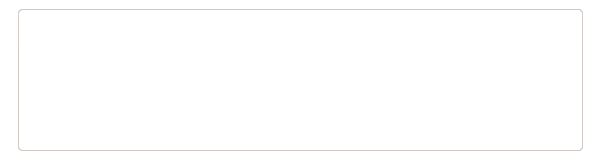
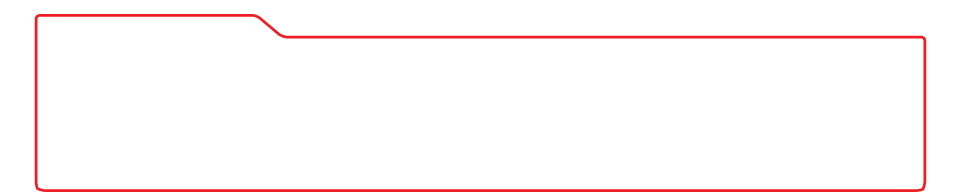
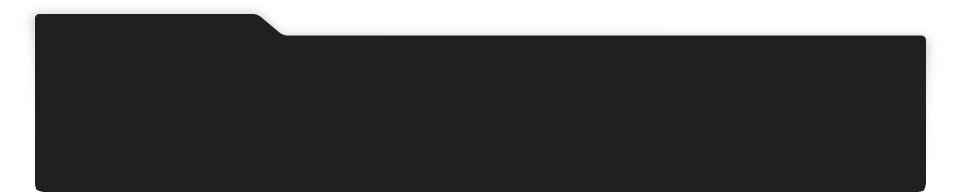
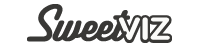
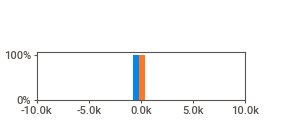
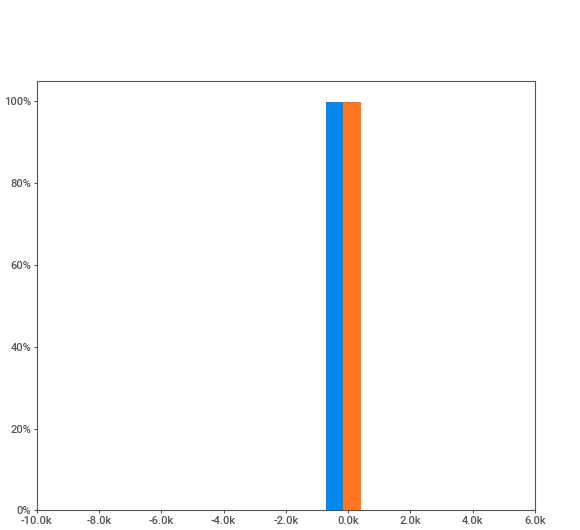
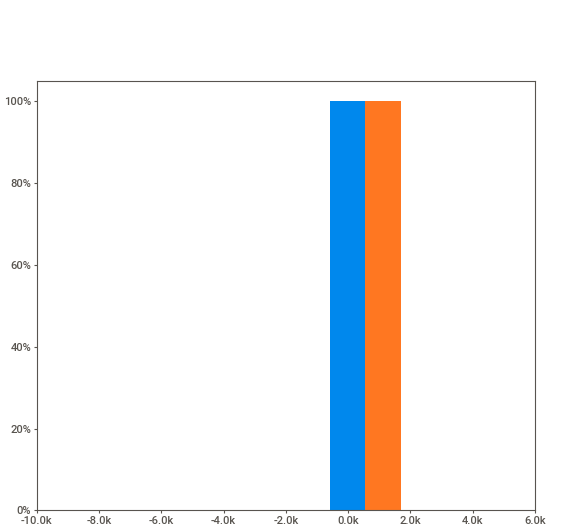
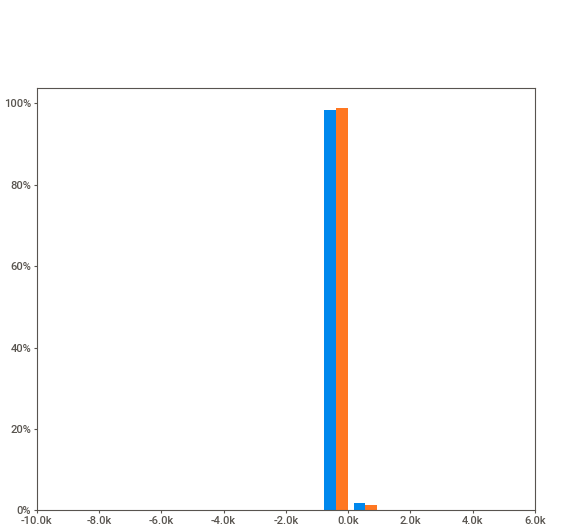
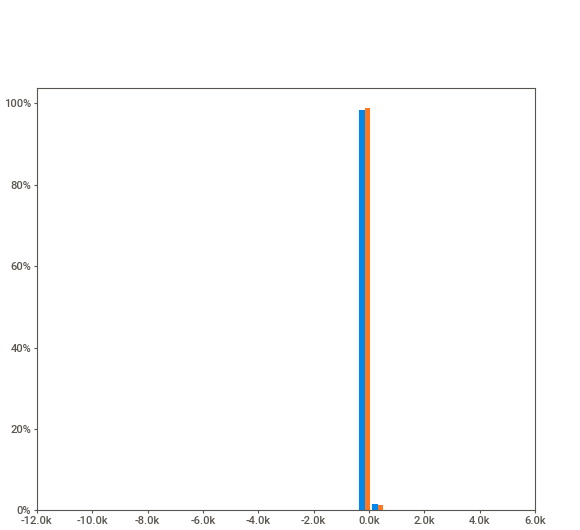
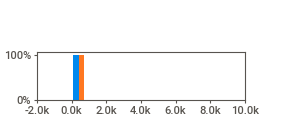
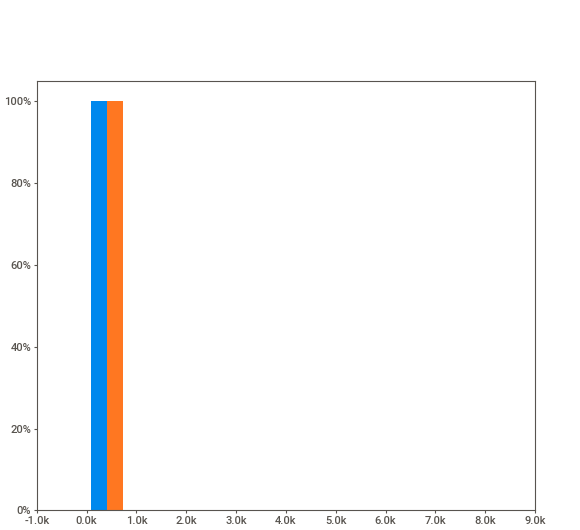
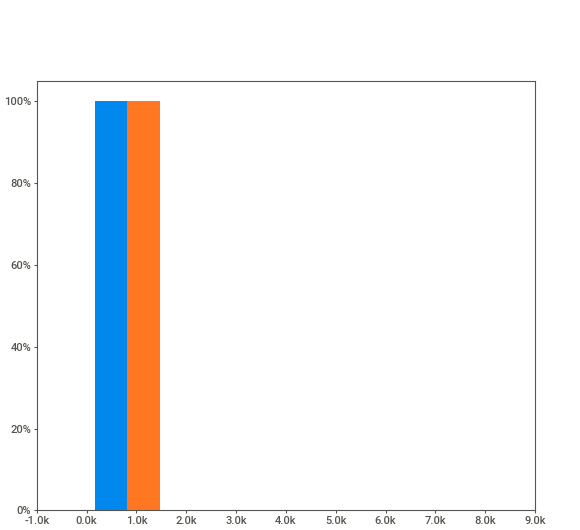
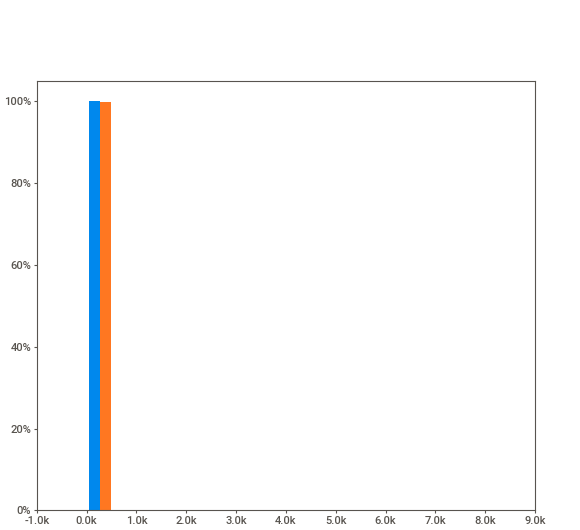
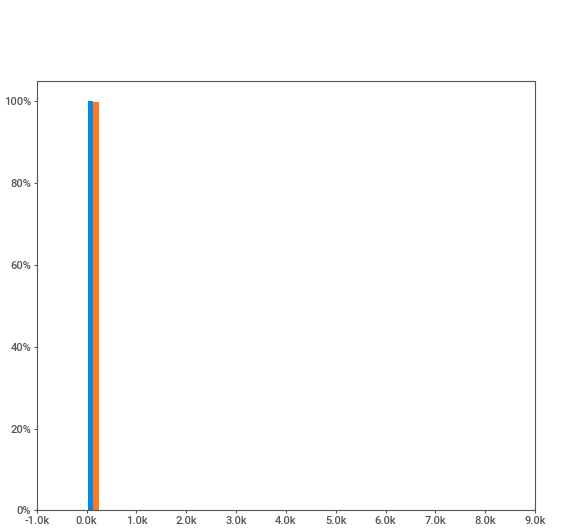
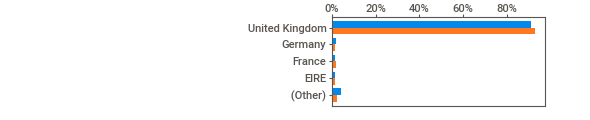
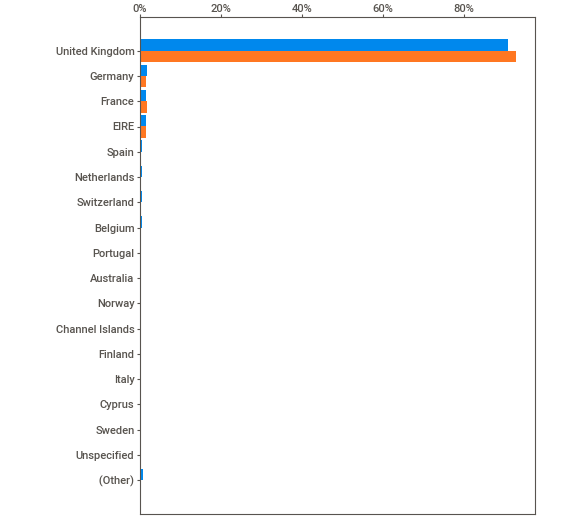
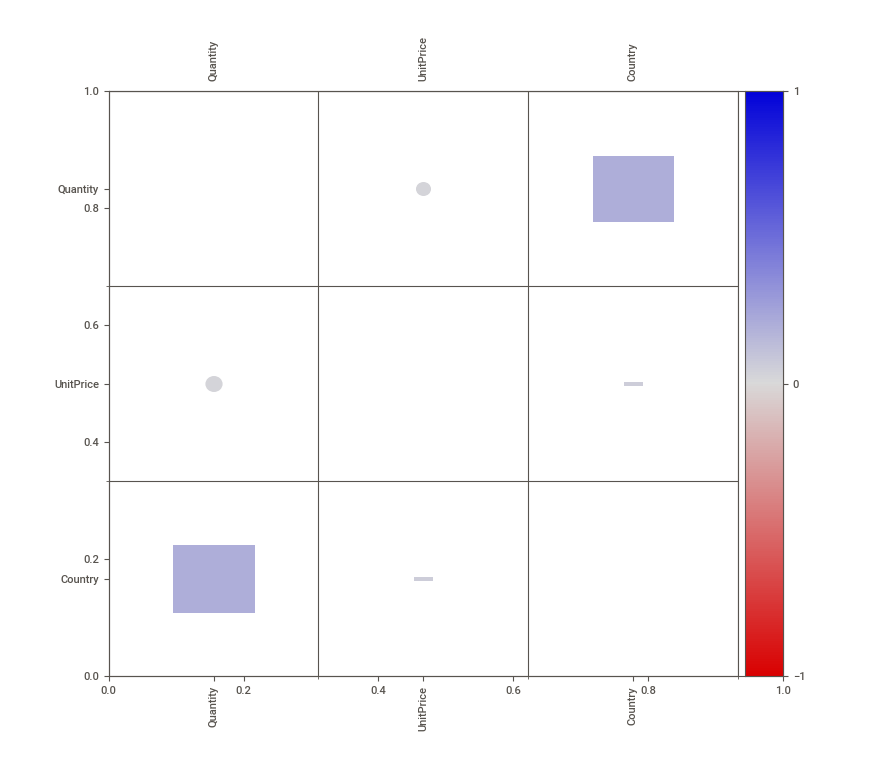
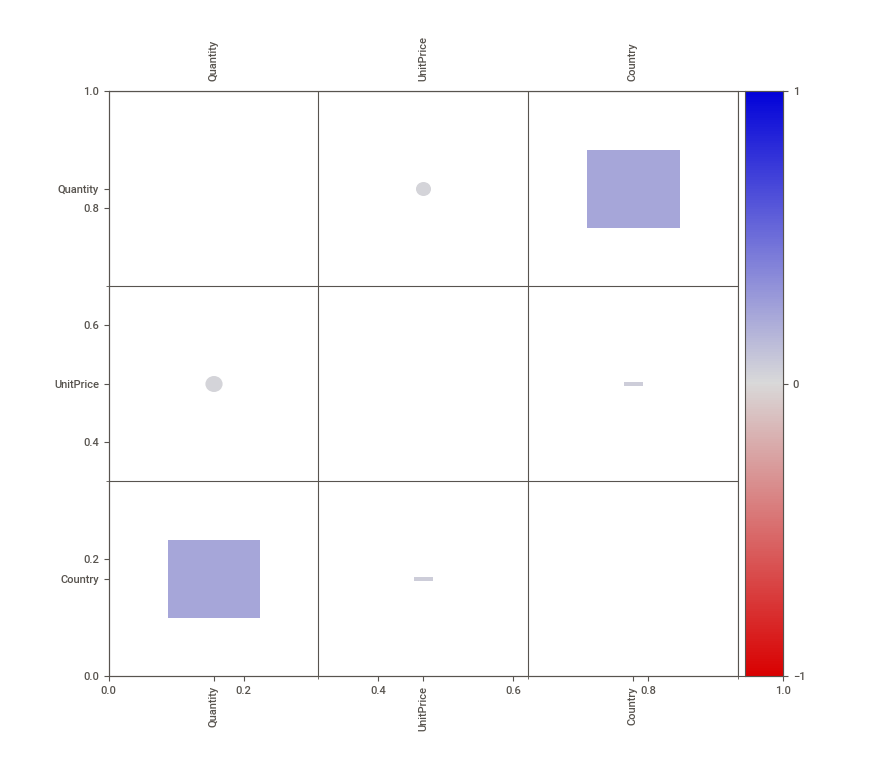

In [38]:
# Sales se excluye para comparar solo las columnas originales
is_train_val = clean['InvoiceDate'] < TEST_START
cmp_split = sv.compare_intra(clean.drop(columns='Sales'), is_train_val, ['train + validación', 'test'])
report = report_file('sweetviz', '4_sweetviz_train_vs_test.html')
cmp_split.show_html(str(report), open_browser=False, layout='vertical')
show_report(report)

In [39]:
# Resumen numérico de la comparación
period = np.where(is_train_val, 'train + validación', 'test')
dias = clean.groupby(period)['InvoiceDate'].apply(lambda s: s.dt.normalize().nunique())
pd.DataFrame({
    'días con ventas': dias,
    'facturas / día': clean.groupby(period)['InvoiceNo'].nunique() / dias,
    'líneas / factura': clean.groupby(period).size() / clean.groupby(period)['InvoiceNo'].nunique(),
    'UnitPrice medio': clean.groupby(period)['UnitPrice'].mean(),
    '% UK': clean.assign(uk=clean['Country'] == 'United Kingdom').groupby(period)['uk'].mean() * 100,
})

,días con ventas,facturas / día,líneas / factura,UnitPrice medio,% UK
test,27,124.00,26.62,3.79,92.92
train + validación,278,72.23,22.13,3.77,91.01


- El test tiene **124 facturas por día** frente a 72 en train + validación, y más líneas por factura (26,6 frente a 22,1).
- El precio medio (~£3,8) y el peso del Reino Unido (91-93%) apenas cambian: la subida de ventas viene del **volumen de pedidos**, no del precio ni del país.

## 8. Transformación de datos

### 8.1. Variable objetivo: ventas netas diarias

La variable `Ventas` por día no existe en el dataset: se crea sumando `Quantity × UnitPrice` de todas las líneas de cada día.

**Días sin actividad:** modelamos solo **días de actividad** (no rellenamos con 0): el periodo de test tampoco contiene sábados ni festivos, así que rellenar con ceros solo añadiría días que nunca habrá que predecir y distorsionaría la media.

Días en el rango: 374
Días con actividad: 305
¿Algún sábado? False


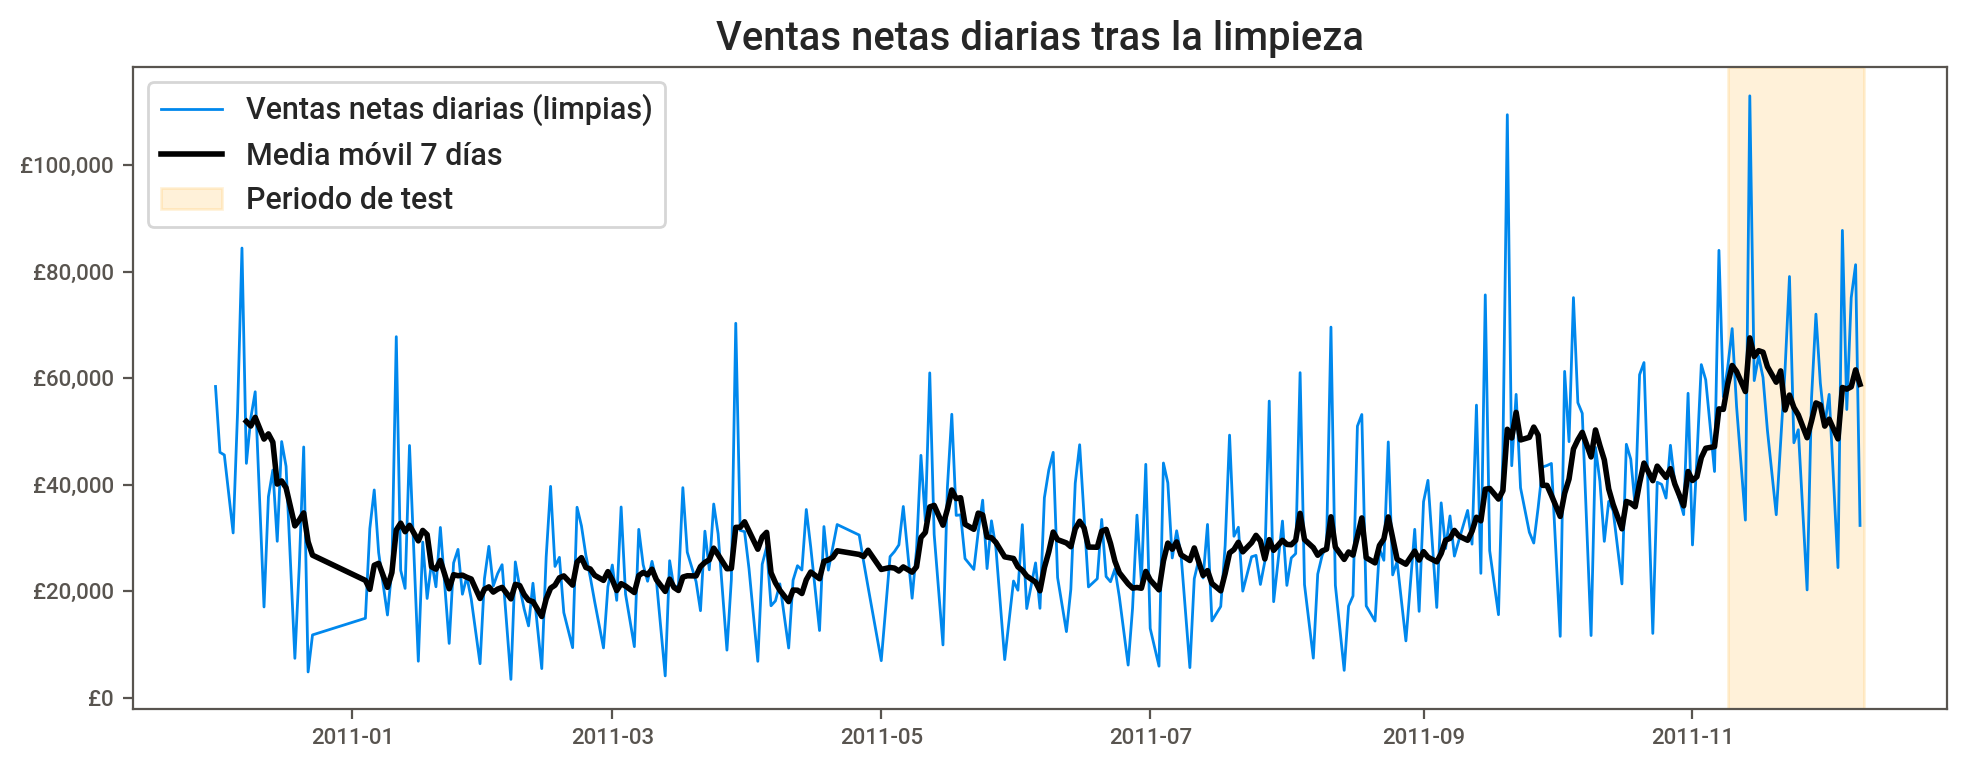

In [40]:
daily = (clean.assign(Date=clean['InvoiceDate'].dt.normalize())
              .groupby('Date')
              .agg(Sales=('Sales', 'sum'),
                   n_invoices=('InvoiceNo', 'nunique'))
              .asfreq('D'))
print('Días en el rango:', len(daily))
daily = daily.dropna(subset=['Sales'])
print('Días con actividad:', len(daily))
print('¿Algún sábado?', (daily.index.dayofweek == 5).any())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.index, daily['Sales'], lw=1, label='Ventas netas diarias (limpias)')
ax.plot(daily.index, daily['Sales'].rolling(7).mean(), lw=2, color='black', label='Media móvil 7 días')
ax.axvspan(TEST_START, TEST_END + pd.Timedelta(days=1), color='orange', alpha=.15, label='Periodo de test')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))
ax.set_title('Ventas netas diarias tras la limpieza'); ax.legend()
plt.tight_layout(); plt.show()

#### Diagnóstico de la serie (prism-eda `time_series`)

Se ejecuta sobre la serie **ya limpia**. `horizon=27` son los días de actividad del periodo de test.

> table.Sales: not ready to forecast. Top issue — 69 period(s) were never recorded. 2 prioritized issue(s) (1 high, 1 medium). 6 alert(s) describe what is in the series. Sampling or recoverable caveats apply.

Informe: [eda_reports/combinado/prism/html/5_prism_serie_diaria.html](eda_reports/combinado/prism/html/5_prism_serie_diaria.html)


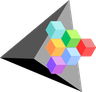

| Severidad | Hallazgo | Detalle | Recomendación |
|:------|:------------|:------------------|:---------------|
| high | 69 period(s) were never recorded | 55 block(s) of the time axis have no row at all (18.4% of the span). The longest runs 11 daily period(s) from 2010-12-24. | A run of absent rows is a collection failure, not a quiet period. Confirm which before filling it. |
| medium | Observations are not evenly spaced | Only 82% of gaps match the dominant daily spacing, across 5 distinct gap length(s). | Every structural result below is computed on a regularized reconstruction. Decide whether that reconstruction is faithful before relying on them. |
| medium | 2 level shifts in the series | The most recent is 2011-11-03, where the level stepped up (+42%) and stayed there. | Training across a real level shift teaches a model the average of two regimes that never existed. Consider training only on the most recent one. |
| low | The level moves over time | Both tests agree the level moves. Difference the series, or use a model that handles a trend directly. | Non-stationarity is a property of the series, not a defect — most series with a trend are non-stationary. |
| low | The series became harder to predict | Around 2011-08-25 the spread went wider, from 6,929 to 1.09e+04. | Prediction intervals fitted on the whole history will be wrong on both sides of this point. |
| low | Spread changes too much for a single outlier rule | 4% of periods fall outside a fence built from the whole history, which means the spread is not constant rather than that the series is full of anomalies. | Read the variance-shift finding instead; a single outlier threshold is the wrong instrument here. |
| low | Some weekly seasonality | A weekly cycle explains 49% of what is left after the trend, with a peak-to-trough swing of 7.056e+04. | Use a model with a seasonal term, and never validate on a window shorter than one full cycle. |
| low | The level is rising | Trend explains 60% of the non-seasonal variation, moving the level by 2,724 across the history. | A model without a trend term will drift steadily wrong as the horizon lengthens. |

In [41]:
import prism_eda as pe

ts_result = pe.time_series(daily.reset_index()[['Date', 'Sales']], value='Sales', timestamp='Date', horizon=27)
show_findings(ts_result, '5_prism_serie_diaria.html')

![](eda_reports/combinado/prism/capturas/prism_serie.png)

**Qué mirar:** las líneas discontinuas marcan los cambios de nivel detectados. La de la derecha es el salto del +42% del 03/11/2011, seis días antes de que empiece el test. Un modelo entrenado con todo el año tenderá a quedarse corto; conviene dar más peso al periodo reciente o usar variables que capten la tendencia.

**Lectura de los hallazgos**

- **69 periodos sin registro**: son los sábados y festivos, es decir, cierres de la tienda y no fallos de recogida de datos.
- **Estacionalidad semanal** (explica ~49% de la variación sin tendencia) → el día de la semana debe ser una variable del modelo.
- **La dispersión aumenta** desde finales de agosto (de ~£6.900 a ~£10.900).

### 8.2. Outliers en la variable objetivo

In [42]:
q1, q3 = daily['Sales'].quantile([.25, .75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out = daily[(daily['Sales'] < low) | (daily['Sales'] > high)]
print(f'Rango IQR (k=1.5): £{low:,.0f} – £{high:,.0f}')
print(f'Días fuera de rango: {len(out)} ({len(out) / len(daily):.1%})')
out.assign(DayOfWeek=out.index.day_name())

Rango IQR (k=1.5): £-10,956 – £74,960
Días fuera de rango: 10 (3.3%)


,Sales,n_invoices,DayOfWeek
Date,,,
2010-12-07,"84,418.61",90.00,Tuesday
2011-09-15,"75,623.68",110.00,Thursday
2011-09-20,"109,449.25",75.00,Tuesday
2011-10-05,"75,111.57",101.00,Wednesday
2011-11-07,"83,987.97",107.00,Monday
2011-11-14,"112,994.02",135.00,Monday
2011-11-23,"79,073.45",148.00,Wednesday
2011-12-05,"87,733.25",140.00,Monday
2011-12-07,"75,072.56",117.00,Wednesday


Tras la limpieza, los días fuera del rango IQR son pocos y se concentran en **septiembre-diciembre**: corresponden a la campaña de Navidad, un patrón real que el modelo debe aprender (y que domina el periodo de test). Por eso **no se eliminan** días de la serie.

### 8.3. Nuevas variables de calendario

Al agregar por día se pierde la información de cada transacción. Para predecir un día futuro solo podemos usar información **conocida de antemano**, así que las variables nuevas se derivan de la fecha. Variables como el número de facturas del día (`n_invoices`) no se usarán como entrada del modelo, porque no se conocen hasta que el día termina (*data leakage*); se mantienen solo como referencia.

In [43]:
features = pd.DataFrame(index=daily.index)
features['t'] = (daily.index - TRAIN_START).days          # tendencia
features['DayOfWeek'] = daily.index.dayofweek             # 0 = lunes … 6 = domingo
features['Day'] = daily.index.day
features['Month'] = daily.index.month
features['WeekOfYear'] = daily.index.isocalendar().week.astype(int)
features['WeekOfMonth'] = (daily.index.day - 1) // 7 + 1
features['DaysToChristmas'] = [
    (pd.Timestamp(year=d.year, month=12, day=25) - d).days % 365 for d in daily.index
]
# Codificación cíclica: diciembre (12) y enero (1) quedan cerca
features['Month_sin'] = np.sin(2 * np.pi * features['Month'] / 12)
features['Month_cos'] = np.cos(2 * np.pi * features['Month'] / 12)

data = features.join(daily)
data.head()

,t,DayOfWeek,Day,Month,WeekOfYear,WeekOfMonth,DaysToChristmas,Month_sin,Month_cos,Sales,n_invoices
Date,,,,,,,,,,,
2010-12-01,0,2,1,12,48,1,24,-0.00,1.00,"58,431.36",133.00
2010-12-02,1,3,2,12,48,1,23,-0.00,1.00,"46,073.32",164.00
2010-12-03,2,4,3,12,48,1,22,-0.00,1.00,"45,571.13",75.00
2010-12-05,4,6,5,12,48,1,20,-0.00,1.00,"30,931.67",95.00
2010-12-06,5,0,6,12,49,1,19,-0.00,1.00,"53,598.44",120.00


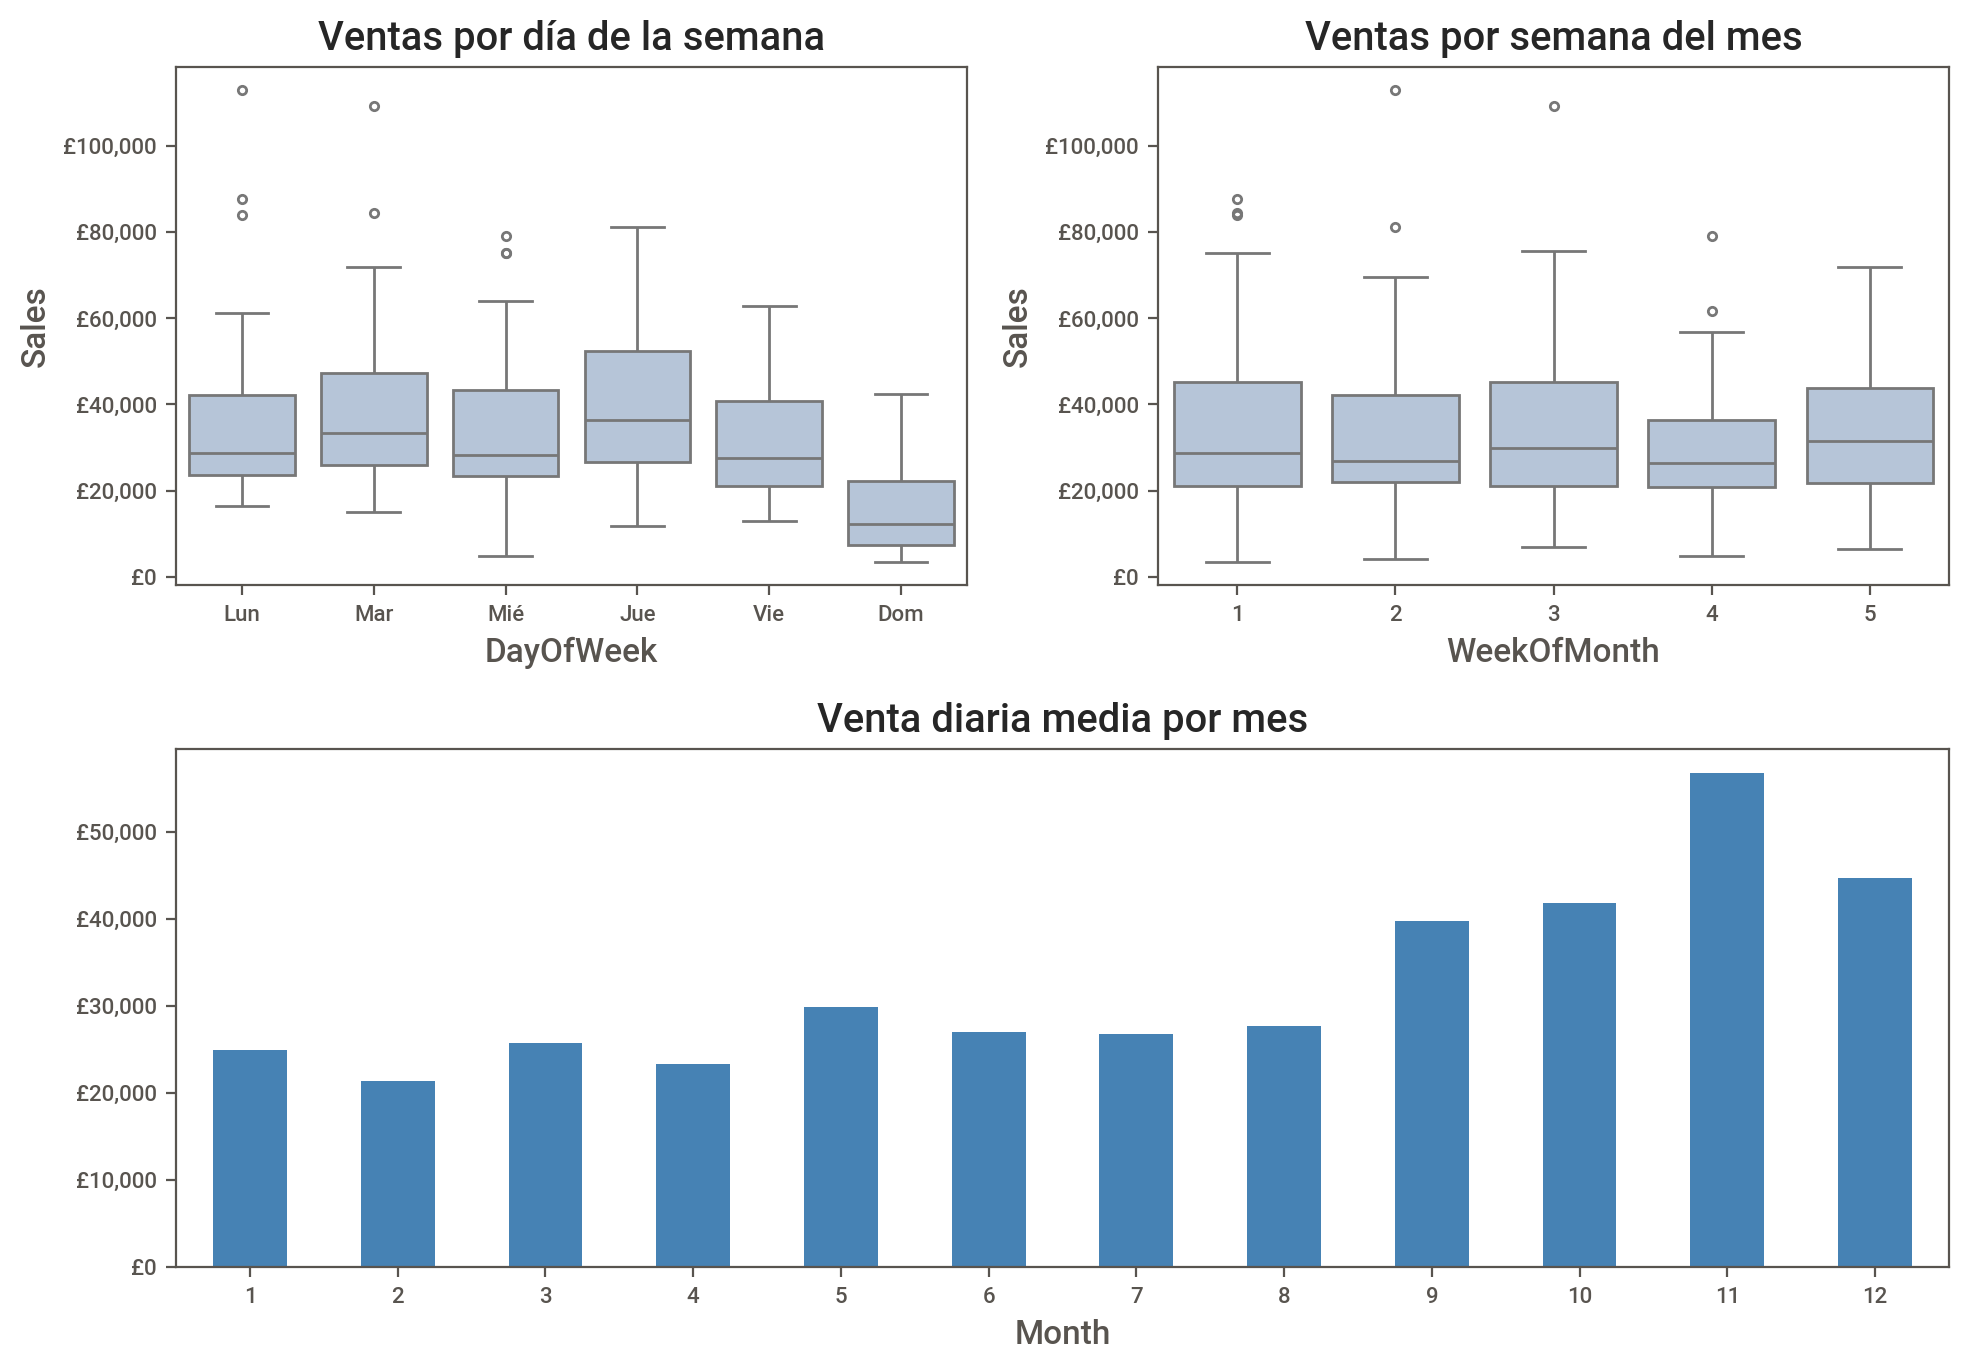

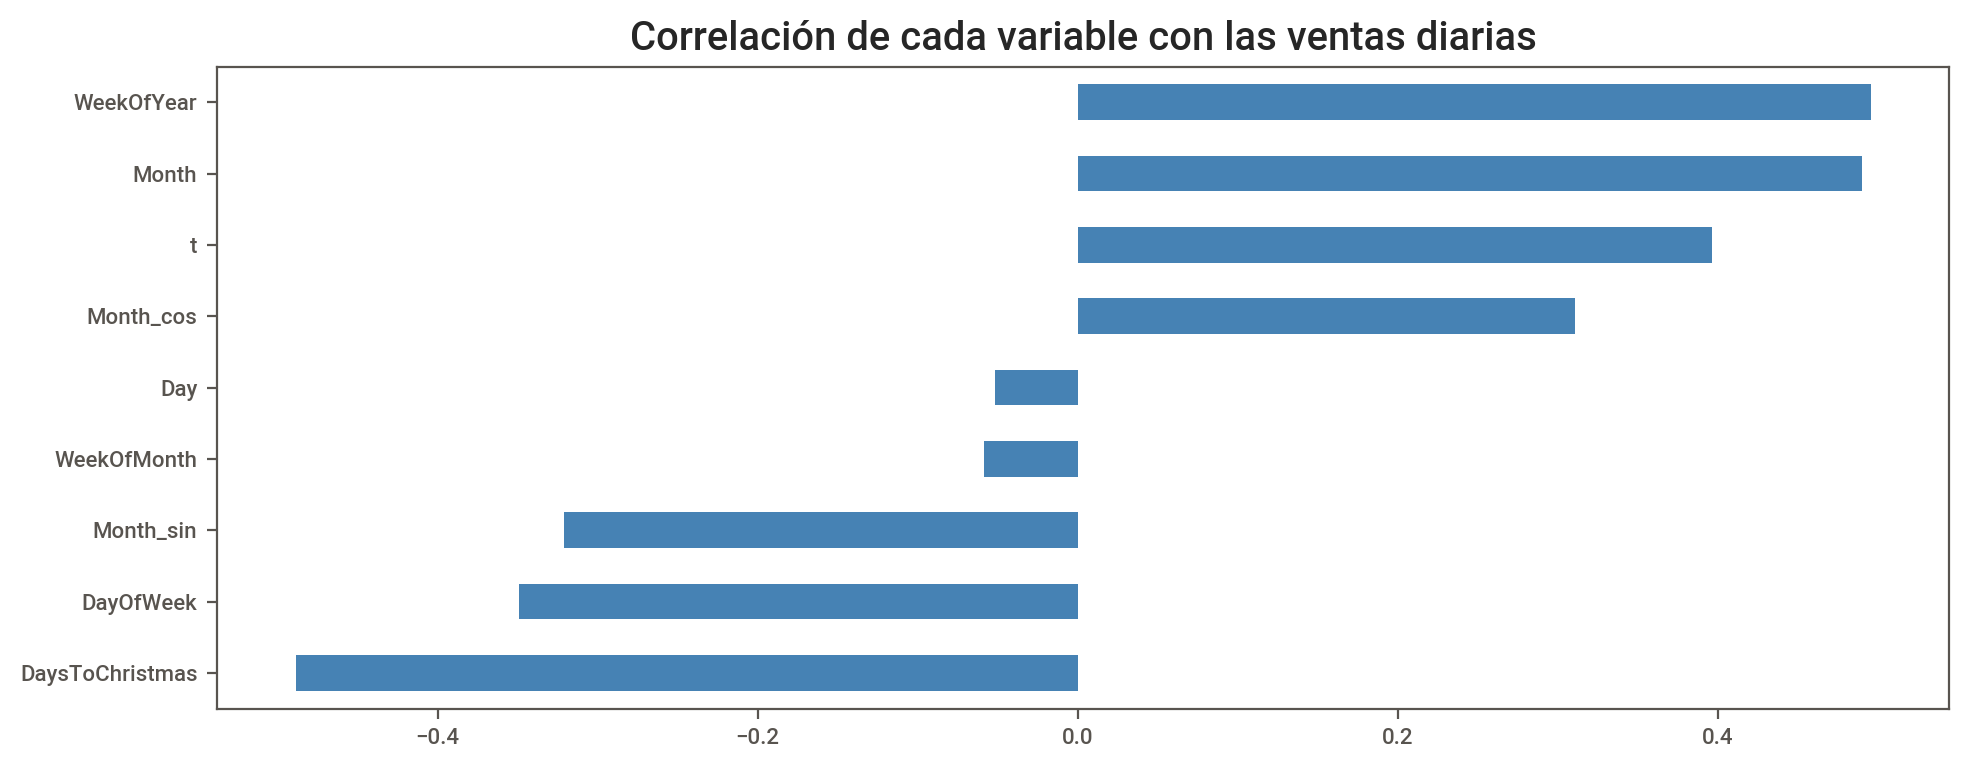

In [44]:
fig, axes = plt.subplot_mosaic([['dia', 'semana'], ['mes', 'mes']], figsize=(10, 7))
sns.boxplot(data=data, x='DayOfWeek', y='Sales', ax=axes['dia'], color='lightsteelblue')
axes['dia'].set_xticks(range(6), ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Dom'])
axes['dia'].set_title('Ventas por día de la semana')
sns.boxplot(data=data, x='WeekOfMonth', y='Sales', ax=axes['semana'], color='lightsteelblue')
axes['semana'].set_title('Ventas por semana del mes')
data.groupby('Month')['Sales'].mean().plot.bar(ax=axes['mes'], color='steelblue', rot=0)
axes['mes'].set_title('Venta diaria media por mes')
for ax in axes.values():
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))
plt.tight_layout(); plt.show()

data.drop(columns='n_invoices').corr()['Sales'].drop('Sales').sort_values().plot.barh(color='steelblue', figsize=(10, 4))
plt.title('Correlación de cada variable con las ventas diarias'); plt.tight_layout(); plt.show()

- El **día de la semana** influye: el domingo vende claramente menos y jueves/martes son los días más fuertes → se codifica con *one-hot*.
- La **tendencia** (`t`), el mes y la cercanía a Navidad están muy correlacionadas con las ventas: el negocio crece y la campaña navideña dispara las ventas.
- La semana del mes tiene un efecto débil; se mantiene y el modelo decidirá si le es útil.

### 8.4. Diagnóstico para regresión (prism-eda `regression`)

Se analizan las variables de calendario anteriores, con el día de la semana como categoría.

/home/eze/IA-BigData/venv_autoeda/lib/python3.12/site-packages/prism_eda/analysis/regression_probe.py:536: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  fitted = sm.OLS(actual.to_numpy(dtype="float64"), matrix).fit()


> table.Sales: review before modeling. Top issue — 7 rows worth reviewing. 1 prioritized issue(s) (1 medium). 6 alert(s) are listed separately.

Informe: [eda_reports/combinado/prism/html/6_prism_regresion.html](eda_reports/combinado/prism/html/6_prism_regresion.html)


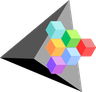

| Severidad | Hallazgo | Detalle | Recomendación |
|:------|:------------|:------------------|:---------------|
| medium | Redundant features carry the same information | WeekOfYear and DaysToChristmas correlate at 0.9998 and 3 more pairs. Predictions are largely unaffected; individual coefficients are not interpretable. | Keep one of each pair, or use a regularized model and stop reading individual coefficients. |
| medium | 7 rows worth reviewing | These rows are extreme in the features, badly fitted, or both, so they move the fit more than any other rows. | Open them before modelling: a data-entry error and a genuinely unusual customer look identical here and need opposite treatment. |
| low | Target is strongly right skewed | Sales has skewness +1.18. A yeo_johnson transform reduces skew to +0.01. | Skew is a property, not a defect. Transform only if the residual diagnostics below show the fit suffering for it. |
| low | Month_sin relates to the target non-linearly | A straight line explains 10.3% of the target, but a binned fit explains 33.3%. A linear model will under-use this feature. | Add a spline, a bucketed version, or use a model that fits curves. |
| low | t relates to the target non-linearly | A straight line explains 15.7% of the target, but a binned fit explains 34.9%. A linear model will under-use this feature. | Add a spline, a bucketed version, or use a model that fits curves. |
| low | Month_cos relates to the target non-linearly | A straight line explains 9.7% of the target, but a binned fit explains 19.9%. A linear model will under-use this feature. | Add a spline, a bucketed version, or use a model that fits curves. |
| low | Parts of the range have almost no support | WeekOfMonth has a gap covering 25% of its range. Predictions there are extrapolation, however confident the model looks. | Constrain predictions to the supported range, or gather examples in the gap. |

In [45]:
reg_data = data.drop(columns='n_invoices').assign(DayOfWeek=data.index.day_name())
reg_result = pe.regression(reg_data.reset_index(drop=True), target='Sales')
show_findings(reg_result, '6_prism_regresion.html')

![](eda_reports/combinado/prism/capturas/prism_filas_revisar.png)

**Qué mirar:** las filas son posiciones dentro de la serie de días de actividad. Las 235 (20/09/2011, £109.449) y 282 (14/11/2011, £112.994) son las que más superan lo esperado, y la 282 ya cae en el periodo de test. Las 18 y 19 (22 y 23/12/2010) quedan muy por debajo, justo antes del parón de Navidad. Son días reales, así que, como en la sección 8.2, no se eliminan.

**Lectura de los hallazgos**

- **Variables redundantes**: `WeekOfYear`, `DaysToChristmas` y `Month` dan casi la misma información (correlación > 0,99), igual que `Day` y `WeekOfMonth` (0,97). Por eso, al ejecutar la celda, aparece el aviso `SingularMatrixWarning`. Las predicciones apenas se ven afectadas, pero los coeficientes individuales no son interpretables: en modelos lineales conviene quedarse con una de cada grupo o regularizar.
- **Target asimétrico** (+1,18): la transformación **Yeo-Johnson** lo deja en ~0. Es una opción a probar en modelos lineales o polinómicos; para árboles (Random Forest, XGBoost) no es necesaria.
- **`t` tiene relación no lineal** con las ventas: una recta explica el 15,7% y un ajuste por tramos el 34,9%. `Month_sin` y `Month_cos` muestran el mismo patrón. Encaja con el salto de nivel de noviembre → mejor regresión polinómica, *splines* o modelos de árboles que una regresión lineal simple.
- **`WeekOfMonth` tiene un hueco del 25% de su rango**, así que las predicciones en esa zona son extrapolación y menos fiables.

### 8.5. Codificación de variables categóricas

In [46]:
DOW_NAMES = {0: 'Mon', 1: 'Tue', 2: 'Wed', 3: 'Thu', 4: 'Fri', 6: 'Sun'}
dow_dummies = pd.get_dummies(data['DayOfWeek'].map(DOW_NAMES), prefix='DOW', dtype=int)
model_data = pd.concat([data.drop(columns=['DayOfWeek', 'n_invoices']), dow_dummies], axis=1)
model_data.head()

,t,Day,Month,WeekOfYear,WeekOfMonth,DaysToChristmas,Month_sin,Month_cos,Sales,DOW_Fri,DOW_Mon,DOW_Sun,DOW_Thu,DOW_Tue,DOW_Wed
Date,,,,,,,,,,,,,,,
2010-12-01,0,1,12,48,1,24,-0.00,1.00,"58,431.36",0,0,0,0,0,1
2010-12-02,1,2,12,48,1,23,-0.00,1.00,"46,073.32",0,0,0,1,0,0
2010-12-03,2,3,12,48,1,22,-0.00,1.00,"45,571.13",1,0,0,0,0,0
2010-12-05,4,5,12,48,1,20,-0.00,1.00,"30,931.67",0,0,1,0,0,0
2010-12-06,5,6,12,49,1,19,-0.00,1.00,"53,598.44",0,1,0,0,0,0


## 9. División en entrenamiento, validación y test

Al ser una **serie temporal**, la división es cronológica (nunca aleatoria): el modelo solo puede aprender del pasado.

- **Entrenamiento:** 01/12/2010 – 08/10/2011
- **Validación:** 09/10/2011 – 08/11/2011 (un mes, misma duración que el test)
- **Test:** 09/11/2011 – 09/12/2011

In [47]:
VAL_START = pd.Timestamp('2011-10-09')

train = model_data.loc[:VAL_START - pd.Timedelta(days=1)]
val   = model_data.loc[VAL_START:TEST_START - pd.Timedelta(days=1)]
test  = model_data.loc[TEST_START:TEST_END]

pd.DataFrame({
    'desde':  [s.index.min().date() for s in (train, val, test)],
    'hasta':  [s.index.max().date() for s in (train, val, test)],
    'días':   [len(s) for s in (train, val, test)],
    '% días': [len(s) / len(model_data) * 100 for s in (train, val, test)],
    'venta media (£)': [s['Sales'].mean() for s in (train, val, test)],
}, index=['train', 'validación', 'test'])

,desde,hasta,días,% días,venta media (£)
train,2010-12-01,2011-10-07,251,82.30,"29,029.11"
validación,2011-10-09,2011-11-08,27,8.85,"43,037.92"
test,2011-11-09,2011-12-09,27,8.85,"57,721.09"


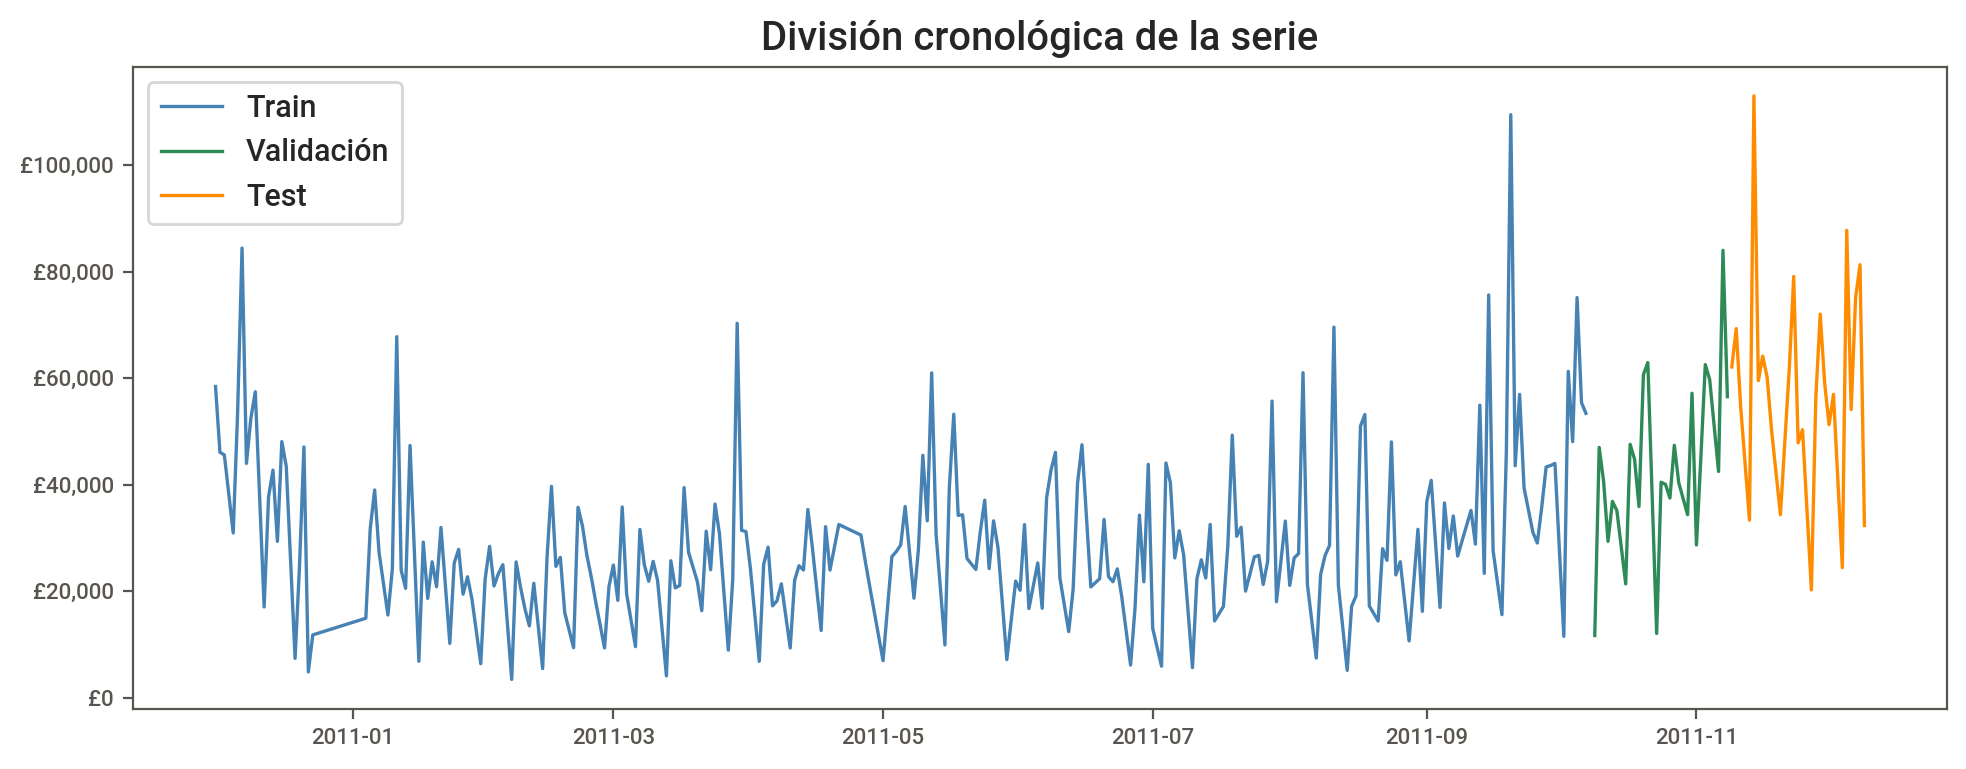

In [48]:
fig, ax = plt.subplots(figsize=(10, 4))
for name, part, color in [('Train', train, 'steelblue'), ('Validación', val, 'seagreen'), ('Test', test, 'darkorange')]:
    ax.plot(part.index, part['Sales'], color=color, label=name, lw=1.2)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))
ax.set_title('División cronológica de la serie'); ax.legend()
plt.tight_layout(); plt.show()

El **80% de los días** queda en entrenamiento (dentro del rango 80-95% de la guía). La venta media de validación y sobre todo de test es más alta que la de entrenamiento, así que el modelo tendrá que **extrapolar la tendencia** y la estacionalidad.

### 9.1. Escalado

In [49]:
from sklearn.preprocessing import MinMaxScaler

TARGET = 'Sales'
FEATURES = [c for c in model_data.columns if c != TARGET]
NUM_FEATURES = ['t', 'Day', 'Month', 'WeekOfYear', 'WeekOfMonth', 'DaysToChristmas']

X_train, y_train = train[FEATURES].copy(), train[TARGET]
X_val,   y_val   = val[FEATURES].copy(),   val[TARGET]
X_test,  y_test  = test[FEATURES].copy(),  test[TARGET]

# El scaler se ajusta SOLO con train para no filtrar información de validación/test
x_scaler = MinMaxScaler().fit(X_train[NUM_FEATURES])
for X in (X_train, X_val, X_test):
    X[NUM_FEATURES] = x_scaler.transform(X[NUM_FEATURES])

y_scaler = MinMaxScaler().fit(y_train.to_frame())
y_train_s = y_scaler.transform(y_train.to_frame()).ravel()
y_val_s   = y_scaler.transform(y_val.to_frame()).ravel()

print('Shapes  X_train', X_train.shape, '| X_val', X_val.shape, '| X_test', X_test.shape)
X_train.describe().T[['min', 'max']].head(8)

Shapes  X_train (251, 14) | X_val (27, 14) | X_test (27, 14)


,min,max
t,0.00,1.00
Day,0.00,1.00
Month,0.00,1.00
WeekOfYear,0.00,1.00
WeekOfMonth,0.00,1.00
DaysToChristmas,0.00,1.00
Month_sin,-1.00,1.00
Month_cos,-1.00,1.00


- Se usa **Min-Max** porque, tras la limpieza, no quedan valores extremos en las variables de entrada (son todas de calendario y acotadas).
- El escalado de la variable objetivo (`y_scaler`) es útil para modelos sensibles a la escala (regresión polinómica, LSTM); para árboles (Random Forest, XGBoost) puede usarse `y_train` sin escalar. Las métricas (RMSE) se calculan siempre en libras, deshaciendo el escalado.
- `t` en validación y test queda por encima de 1: es esperable, son fechas posteriores al entrenamiento.

## 10. Exploración interactiva (opcional): D-Tale

Cambia `RUN_DTALE = True` y ejecuta la celda para abrir el dataset limpio en una interfaz web (filtros, gráficos, nulos, correlaciones…). Cada acción puede exportarse como código pandas. Está desactivado por defecto para que el notebook se pueda ejecutar de principio a fin sin dejar un servidor abierto.

In [50]:
RUN_DTALE = False

if RUN_DTALE:
    import dtale
    d = dtale.show(clean, host='localhost', open_browser=False)
    print('D-Tale disponible en:', d._main_url)
    # d.kill()  # para pararlo

## Siguiente paso

Entrenar los modelos de regresión (baseline, regresión polinómica, Random Forest, XGBoost, …) sobre `X_train`/`y_train`, ajustar hiperparámetros con `X_val`/`y_val` y evaluar el modelo final con RMSE sobre `X_test`/`y_test`.